# Sujet 4 expliqué depuis zéro · la file d'attente M/M/1

Version « cours » du notebook de rendu [s4_1_file_mm1.ipynb](s4_1_file_mm1.ipynb) : mêmes calculs,
**même graine (2026), même ordre de tirages**, donc les mêmes chiffres, mais tout est repris depuis
le début pour que tu puisses le **réexpliquer au jury**.

**Mode d'emploi.** Lis dans l'ordre, exécute chaque cellule (*Run All* fonctionne), fais les
exercices ✋ avant d'ouvrir les corrigés, puis entraîne-toi à dire les blocs 🗣️ à voix haute.

| Symbole | Bloc | Contenu |
|---|---|---|
| 🎯 | Objectif | ce qu'on demande vraiment |
| 💡 | Intuition | l'idée en une phrase + une figure |
| 🧮 | Calcul | les étapes, chacune justifiée |
| 🐍 | Code | la vraie fonction de `src/stats_td/`, expliquée |
| 📊 | Lecture | ce que disent les chiffres réels |
| ⚠️ | Pièges | erreurs classiques, coquilles |
| ✋ | À toi | exercice + corrigé replié |
| 🗣️ | 30 s | la réponse à dire au jury |
| 🎤 | Jury | questions probables ([questions_oral.md](questions_oral.md)) |

**Plan.** Préparation · Partie 0 (les bases) · A.1 · A.2 · A.3 (loi exponentielle) · B.1 · B.2 · B.3
(processus de Poisson) · S.1 · S.2 (simulation) · Q1 à Q5 (file M/M/1) · Récap.

**Ordre des tirages.** Pour retrouver exactement les chiffres du rendu, les tirages aléatoires sont
faits dans le même ordre que dans le notebook de rendu ; c'est pourquoi la vérification numérique de
B.3 ($N_3$) est faite en S.2, juste après celle de $\mathcal P(4)$. Les figures d'intuition utilisent
un générateur **à part** (`rng_fig`) et les exercices un autre (`rng_exo`).

## Préparation

La cellule suivante charge les outils. Ligne par ligne :
- `sys.path.insert(...)` : dit à Python où trouver notre code (`src/stats_td/`) ;
- `inspect` : permet d'afficher le code source d'une fonction (blocs 🐍) ;
- `style()` : réglages communs des figures ;
- `rng = np.random.default_rng(GRAINE)` : **le** générateur aléatoire, graine 2026. Tous les
  tirages « officiels » passent par lui, dans le même ordre que le notebook de rendu ;
- `rng_fig` : un générateur à part pour les figures d'intuition (pour ne pas décaler `rng`).

In [1]:
import inspect, sys
from math import factorial
from pathlib import Path
sys.path.insert(0, str(Path("../../src").resolve()))   # pour importer stats_td

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats                                  # tests (KS, chi2) et lois de référence
from stats_td.figures import style, VIOLET, ROUGE, GRIS
from stats_td.generateurs import exponentielle_inversion
from stats_td.empirique import repartition_complementaire
from stats_td.files_attente import (nombre_points_poisson, poisson_comptage, file_mm1,
                                    file_mm1_vectorisee, file_mm1_evenements, longueur_recurrence,
                                    longueur_lindley, loi_stationnaire, indicateurs_theoriques,
                                    moyenne_par_lots)

style()
GRAINE = 2026
rng = np.random.default_rng(GRAINE)     # même graine que le notebook de rendu
rng_fig = np.random.default_rng(1)      # générateur réservé aux figures d'intuition
resultats = {}                          # (le rendu y range ses chiffres ; ici on ne sauve rien)
virgule = lambda s: s.replace(".", ",")

## Partie 0 · Les bases

### 0.1 Une variable aléatoire « durée »
Tu attends le bus. Le temps d'attente $X$ (en minutes) est **aléatoire** : on ne connaît pas sa
valeur à l'avance, mais on connaît sa **loi**, c'est-à-dire les probabilités de ses valeurs.
- **Fonction de répartition** : $F(x) = P(X \le x)$ (probabilité d'avoir attendu au plus $x$).
- **Répartition complémentaire** (ou fonction de survie) : $F^c(x) = P(X \ge x)$, probabilité
  d'attendre **encore** au moins $x$. Pour une variable à densité, $F^c = 1 - F$.
- **Densité** $f$ : $P(a \le X \le b) = \int_a^b f(x)\,dx$, et $f = F'$. On la dessine comme un
  histogramme « infiniment fin ».
- **Indicatrice** $\mathbb 1_A$ : vaut 1 si la condition $A$ est vraie, 0 sinon. Par exemple
  $\mathbb 1_{\mathbb R^+}(x) = 1$ si $x \ge 0$. $\mathbb R^{*-}$ désigne les réels **strictement**
  négatifs.
- La notation $X \sim \mathcal E(\lambda)$ se lit « $X$ suit la loi exponentielle de paramètre
  $\lambda$ ».

### 0.2 Moyenne, variance, erreur-type
- **Espérance** (moyenne théorique) : $E[X] = \int x f(x)\,dx$. **Variance** :
  $\operatorname{Var}X = E[(X - E[X])^2] = E[X^2] - E[X]^2$ (formule de König-Huygens).
  **Écart-type** $\sigma = \sqrt{\operatorname{Var}X}$, dans la même unité que $X$.
- **Loi des grands nombres (LGN)** : la moyenne de $T$ tirages indépendants tend vers $E[X]$.
- **Erreur-type** de la moyenne de $T$ tirages **indépendants** : $\sigma/\sqrt T$. Un écart
  « moyenne simulée moins théorie » s'exprime en erreurs-types : moins de 2, c'est courant ; plus de
  3, c'est suspect.
- **Variance empirique** : `x.var(ddof=1)` divise par $T - 1$ (comme `var` de Matlab) ; `ddof=0`
  diviserait par $T$ (biaisé).

### 0.3 Probabilité conditionnelle et indépendance
$P(A \mid B) = P(A \cap B)/P(B)$ (si $P(B) > 0$) : la probabilité de $A$ **sachant** que $B$ s'est
produit. $A$ et $B$ sont **indépendants** si $P(A \cap B) = P(A)P(B)$. Pour deux variables
indépendantes à densité, la densité du couple est le **produit** des densités.

### 0.4 Simuler à partir d'uniformes (rappel du sujet 1)
`rng.random()` donne $U \sim \mathcal U[0, 1]$ : toutes les valeurs de $[0, 1[$ sont « également
probables », et $P(U \le u) = u$. **Méthode d'inversion** : si $F$ est continue et croissante,
$F^{-1}(U)$ a pour fonction de répartition $F$.

### 0.5 Deux lois discrètes
- **Poisson** $\mathcal P(m)$ : $P(N = k) = e^{-m}m^k/k!$, $k = 0, 1, 2, \dots$ Elle compte des
  événements « rares et indépendants » (appels reçus en une minute). Moyenne = variance = $m$.
- **Géométrique** sur $\{0, 1, 2, \dots\}$ : $P(G = k) = (1-r)r^k$ : nombre d'échecs avant le premier
  succès quand chaque essai échoue avec probabilité $r$.

### 0.6 Vocabulaire des files d'attente
Un **serveur** (guichet, processeur) traite des **clients** un par un, dans l'ordre d'arrivée
(**FIFO**). La notation de Kendall **M/M/1** veut dire : arrivées « M » (Poisson, sans **M**émoire),
services « M » (exponentiels), **1** serveur. $\lambda$ = nombre moyen d'arrivées par seconde,
$\mu$ = nombre moyen de clients que le serveur peut traiter par seconde s'il ne s'arrête jamais
(un service dure $1/\mu$ en moyenne). La **charge** $\rho = \lambda/\mu$ compare les deux.

### 0.7 Outils Python utilisés (et leur équivalent Matlab)
| Python | Matlab | rôle |
|---|---|---|
| `rng.random(T)` | `rand(1, T)` | $T$ uniformes |
| `np.log(x)` | `log(x)` | logarithme **népérien** |
| `np.cumsum(x)` | `cumsum(x)` | sommes cumulées (instants $T_k$) |
| `np.mean(L == 0)` | `mean(L == 0)` | fréquence d'un événement (un booléen vaut 0 ou 1) |
| `while cond:` | `while cond ... end` | boucle tant que |
| `max(0, l + 1 - A)` | `max(0, l + 1 - A)` | maximum de deux nombres |
| `np.searchsorted(S, T)` | `histc` | combien de valeurs de `S` sont avant chaque `T` |

### ✋ À toi (Partie 0)
1. Un dé équilibré : calcule $E[X]$ et $\operatorname{Var}X$.
2. Avec `rng_exo`, tire $10^5$ uniformes et vérifie que la fréquence de $\{U \le 0{,}3\}$ vaut
   environ $0{,}3$. Donne l'erreur-type.
(On utilise un générateur **à part**, `rng_exo`, pour ne pas décaler les tirages de `rng`.)

In [2]:
rng_exo = np.random.default_rng(0)   # générateur réservé aux exercices
# 1. E[X] = (1 + ... + 6) / 6 ; Var X = E[X^2] - E[X]^2
# 2. U = rng_exo.random(100_000) ; freq = np.mean(U <= 0.3) ; erreur-type = sqrt(0.3 * 0.7 / 1e5)

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

1. $E[X] = 21/6 = 3{,}5$ ; $E[X^2] = 91/6$ ; $\operatorname{Var}X = 91/6 - 12{,}25 = 35/12 \approx 2{,}92$.
2. ```python
   U = rng_exo.random(100_000)
   print(np.mean(U <= 0.3), np.sqrt(0.3 * 0.7 / 100_000))   # ≈ 0,300 et 0,0014
   ```
   $P(U \le 0{,}3) = 0{,}3$ : c'est la propriété $P(U \le u) = u$ qui sert dans toutes les preuves de
   simulation.

</details>

## A.1 · Moyenne et écart-type de la loi exponentielle

### 🎯 Objectif
> *Énoncé.* Montrer que la loi exponentielle a même moyenne et même écart-type et donner
> l'expression de sa moyenne et de son écart type en fonction de $\lambda$.

**Ce qu'on demande vraiment** : calculer $E[X]$ et $\sigma_X$ pour $X \sim \mathcal E(\lambda)$, et
constater qu'ils sont égaux. La loi est donnée par $F^c(x) = P(X \ge x) = e^{-\lambda x}$ pour
$x \ge 0$ (et 1 pour $x < 0$ : une durée est positive).

### 💡 Intuition
**Une durée exponentielle est courte le plus souvent, parfois longue, et sa moyenne vaut $1/\lambda$.**
Plus $\lambda$ (le « taux ») est grand, plus les durées sont courtes. Sur la figure, la moyenne
(tirets) est aussi l'écart-type.

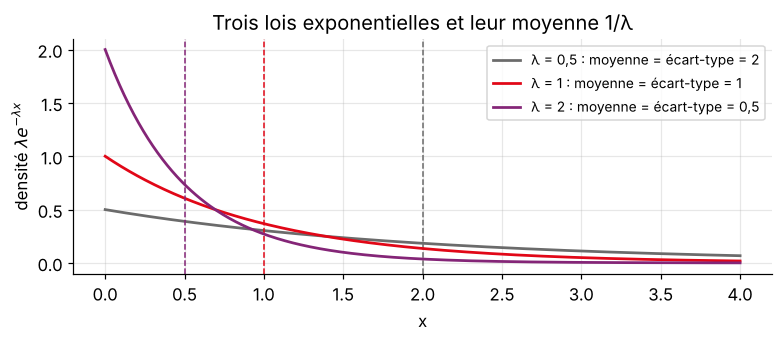

In [3]:
x = np.linspace(0, 4, 400)
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
for lam_i, c in [(0.5, GRIS), (1.0, ROUGE), (2.0, VIOLET)]:
    ax.plot(x, lam_i * np.exp(-lam_i * x), color=c, lw=1.8, label=virgule(f"λ = {lam_i:g} : moyenne = écart-type = {1/lam_i:g}"))
    ax.axvline(1 / lam_i, color=c, ls="--", lw=1)
ax.set_xlabel("x"); ax.set_ylabel(r"densité $\lambda e^{-\lambda x}$"); ax.legend(fontsize=9)
ax.set_title("Trois lois exponentielles et leur moyenne 1/λ"); plt.show()

### 🧮 Calcul
| Étape | Calcul | Pourquoi on a le droit |
|---|---|---|
| 1. Densité | $f(x) = -\frac{d}{dx}F^c(x) = \lambda e^{-\lambda x}$ pour $x \ge 0$ | $F = 1 - F^c$ et $f = F'$ |
| 2. Moyenne | $E[X] = \int_0^\infty x\,\lambda e^{-\lambda x}dx$ | définition de l'espérance |
| 3. IPP | $= [-x e^{-\lambda x}]_0^\infty + \int_0^\infty e^{-\lambda x}dx$ | $u = x$, $v' = \lambda e^{-\lambda x}$, $v = -e^{-\lambda x}$ |
| 4. Crochet nul | $x e^{-\lambda x} \to 0$ en $+\infty$, vaut 0 en 0 | l'exponentielle l'emporte sur $x$ |
| 5. | $E[X] = \frac{1}{\lambda}$ | $\int_0^\infty e^{-\lambda x}dx = 1/\lambda$ |
| 6. Moment 2 | $E[X^2] = [-x^2e^{-\lambda x}]_0^\infty + 2\int_0^\infty x e^{-\lambda x}dx = \frac{2}{\lambda}E[X] = \frac{2}{\lambda^2}$ | même IPP avec $u = x^2$ |
| 7. Variance | $\operatorname{Var}X = \frac{2}{\lambda^2} - \frac{1}{\lambda^2} = \frac{1}{\lambda^2}$ | König-Huygens |
| 8. Écart-type | $\sigma_X = \frac{1}{\lambda}$ | racine (positive) |

$$\boxed{E[X] = \sigma_X = \frac{1}{\lambda}}$$

**Contrôle de cohérence** : unités. Si $\lambda$ est en « par seconde », $1/\lambda$ est en secondes,
comme une durée : c'est cohérent.

### 🐍 Code
On tire $10^5$ valeurs de $\mathcal E(2)$ avec la fonction du sujet 1, `exponentielle_inversion`
(méthode d'inversion, expliquée en S.1). Voici son code :

In [4]:
print(inspect.getsource(exponentielle_inversion))

lam, T = 2.0, 100_000
X = exponentielle_inversion(lam, T, rng)        # Simulation Q1 : X = -ln(1 - U) / λ   (tirage n° 1 de rng)
moy, et = X.mean(), X.std(ddof=1)               # ddof=1 : on divise par T - 1
z_moy = (moy - 1 / lam) / (et / np.sqrt(T))     # écart à 1/λ, en erreurs-types
print(f"1/λ = {1/lam}   moyenne = {moy:.4f} ({z_moy:+.2f} e.-t.)   écart-type = {et:.4f}")
print(f"test KS contre E(2) : p = {stats.kstest(X, 'expon', args=(0, 1/lam)).pvalue:.2f}")

def exponentielle_inversion(lam, T, rng):
    """Loi E(lam) par inversion : Y = F^{-1}(U) = -ln(1 - U) / lam.

    On utilise 1 - U (dans ]0, 1]) plutôt que U (dans [0, 1)) pour ne
    jamais calculer ln(0). Comme 1 - U suit aussi U[0, 1], -ln(U)/lam
    donnerait la même loi.
    """
    if lam <= 0:
        raise ValueError("lambda doit être strictement positif")
    U = uniforme(T, rng)
    return -np.log(1.0 - U) / lam

1/λ = 0.5   moyenne = 0.4976 (-1.51 e.-t.)   écart-type = 0.4986
test KS contre E(2) : p = 0.15


### 📊 Lecture
Moyenne $0{,}498$ et écart-type $0{,}499$, les deux proches de $1/\lambda = 0{,}5$. L'écart de la
moyenne vaut $-1{,}5$ erreur-type ($\sigma/\sqrt T = 0{,}5/316 \approx 0{,}0016$) : c'est courant
(moins de 2). Le test de Kolmogorov-Smirnov compare toute la loi : $p = 0{,}15$, rien d'anormal.
C'est la loi des grands nombres en action.

### ⚠️ Pièges
- Dire « la moyenne vaut $\lambda$ » : non, $\lambda$ est un **taux** (par seconde), la moyenne est $1/\lambda$.
- Confondre variance ($1/\lambda^2$) et écart-type ($1/\lambda$).
- Oublier de soustraire $E[X]^2$ dans la variance.

### ✋ À toi
Pour $\lambda = 4$ : donne $E[X]$, $\operatorname{Var}X$, puis vérifie par simulation avec `rng_exo`
($10^5$ tirages) et donne l'écart en erreurs-types.

In [5]:
# Y = exponentielle_inversion(4.0, 100_000, rng_exo)
# print(Y.mean(), Y.var(ddof=1))  # théorie : 0,25 et 0,0625

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

$E[X] = 0{,}25$, $\operatorname{Var}X = 1/16 = 0{,}0625$, $\sigma = 0{,}25$.
```python
Y = exponentielle_inversion(4.0, 100_000, rng_exo)
print(Y.mean(), Y.var(ddof=1), (Y.mean() - 0.25) / (Y.std(ddof=1) / np.sqrt(len(Y))))
```
L'écart doit être de l'ordre de 1 erreur-type (au plus 2 dans 95 % des cas).

</details>

### 🗣️ La réponse en 30 secondes
<details>
<summary><b>Ce que je dis au jury</b></summary>

« La densité de $\mathcal E(\lambda)$ est $\lambda e^{-\lambda x}$ sur $\mathbb R^+$. Par intégration par
parties, $E[X] = 1/\lambda$ et $E[X^2] = 2/\lambda^2$, donc la variance vaut $1/\lambda^2$ par
König-Huygens et l'écart-type $1/\lambda$ : moyenne et écart-type sont égaux. En simulant $10^5$
valeurs de $\mathcal E(2)$, j'obtiens $0{,}498$ et $0{,}499$ pour $0{,}5$. »

</details>

### 🎤 Jury
Questions 1 et 2 de [questions_oral.md](questions_oral.md). Piège typique : « Donc la moyenne,
c'est $\lambda$ ? » (non, $1/\lambda$ ; vérifie avec les unités).

## A.2 · L'absence de mémoire

### 🎯 Objectif
> *Énoncé.* Montrer que la loi exponentielle est « sans mémoire » c'est-à-dire que
> $(*)\ P(X \ge x + t \mid X \ge x) = P(X \ge t)$.

**Ce qu'on demande vraiment** : sachant qu'on a déjà attendu $x$, la probabilité d'attendre
**encore** au moins $t$ est la même que si on commençait juste. Le passé ne compte pas.

### 💡 Intuition
**Si on coupe la courbe de survie à l'âge $x$ et qu'on la remet à l'échelle, on retrouve exactement
la courbe de départ.** Sur la figure : $G(t) = e^{-\lambda t}$ (violet) et $G(x + t)/G(x)$ pour
$x = 0{,}5$ (tirets rouges) : les deux courbes se superposent.

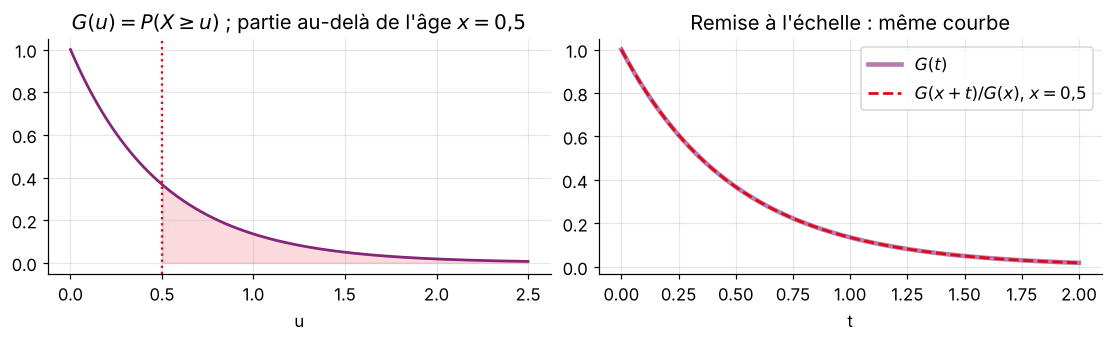

In [6]:
lam_f, x0 = 2.0, 0.5
t = np.linspace(0, 2, 300)
G = lambda u: np.exp(-lam_f * u)
fig, axs = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
u = np.linspace(0, 2.5, 300)
axs[0].plot(u, G(u), color=VIOLET, lw=1.8); axs[0].axvline(x0, color=ROUGE, ls=":")
axs[0].fill_between(u[u >= x0], G(u[u >= x0]), color=ROUGE, alpha=0.15)
axs[0].set_title(r"$G(u) = P(X \geq u)$ ; partie au-delà de l'âge $x = 0{,}5$"); axs[0].set_xlabel("u")
axs[1].plot(t, G(t), color=VIOLET, lw=3, alpha=0.6, label=r"$G(t)$")
axs[1].plot(t, G(x0 + t) / G(x0), "--", color=ROUGE, lw=1.8, label=r"$G(x+t)/G(x)$, $x = 0{,}5$")
axs[1].set_title("Remise à l'échelle : même courbe"); axs[1].set_xlabel("t"); axs[1].legend()
plt.show()

### 🧮 Calcul
| Étape | Calcul | Pourquoi on a le droit |
|---|---|---|
| 1. Définition | $P(X \ge x+t \mid X \ge x) = \frac{P(X \ge x + t,\ X \ge x)}{P(X \ge x)}$ | probabilité conditionnelle, $P(X \ge x) = e^{-\lambda x} > 0$ |
| 2. Inclusion | $\{X \ge x + t\} \subset \{X \ge x\}$, donc l'intersection vaut $\{X \ge x + t\}$ | $t \ge 0$ |
| 3. Remplacer | $= \frac{e^{-\lambda(x+t)}}{e^{-\lambda x}}$ | formule de $F^c$, $x$ et $x + t$ sont $\ge 0$ |
| 4. Simplifier | $= e^{-\lambda t} = P(X \ge t)$ | $e^{a+b} = e^ae^b$ |

$$\boxed{P(X \ge x + t \mid X \ge x) = P(X \ge t)\quad (x, t \ge 0)}$$

**Contrôle** : avec $x = 0$, la formule dit $P(X \ge t) = P(X \ge t)$ : normal, on n'a rien attendu.

### 🐍 Code
Pas de fonction dédiée : on prend les valeurs $X \ge x$, on leur retire $x$ (durée **restante**), et
on calcule la fréquence de $\{\text{reste} \ge t\}$. On réutilise les $X$ de A.1 (aucun nouveau tirage).

In [7]:
ages, t0 = [0.0, 0.5, 1.0], 0.5
reste_expo = [X[X >= x] - x for x in ages]          # durée de vie restante sachant X >= x
p = [np.mean(R >= t0) for R in reste_expo]          # P(X >= x + t0 | X >= x), estimée
print("P(X >= x + 0,5 | X >= x) pour x = 0 ; 0,5 ; 1 :", "  ".join(f"{v:.3f}" for v in p))
print(f"théorie : e^(-λ t) = {np.exp(-lam*t0):.3f} pour tout x")
print("nombre de valeurs utilisées :", [len(R) for R in reste_expo])

P(X >= x + 0,5 | X >= x) pour x = 0 ; 0,5 ; 1 : 0.366  0.368  0.369
théorie : e^(-λ t) = 0.368 pour tout x
nombre de valeurs utilisées : [100000, 36563, 13472]


### 📊 Lecture
$0{,}366$ ; $0{,}368$ ; $0{,}369$ pour les âges 0 ; 0,5 ; 1, contre $e^{-1} = 0{,}368$ : l'âge ne
change rien. Attention, plus $x$ est grand, moins il reste de valeurs $X \ge x$ (environ
$10^5 e^{-2x}$, soit 13 500 pour $x = 1$), donc l'estimation est un peu moins précise pour les grands
âges.

### ⚠️ Pièges
- Oublier de dire **pourquoi** l'intersection vaut $\{X \ge x+t\}$ (c'est l'inclusion, car $t \ge 0$).
- Croire que « sans mémoire » veut dire « l'attente totale est indépendante du passé » : c'est la
  durée **restante** qui a la même loi.
- Pour la file : c'est grâce à cette propriété qu'un client en cours de service a toujours un temps
  restant $\mathcal E(\mu)$ (utilisé en Q1).

### ✋ À toi
Un bus passe selon un délai $X \sim \mathcal E(1/10)$ (en minutes, moyenne 10 min). Tu attends déjà
depuis 5 min. Quelle est la probabilité d'attendre **encore** plus de 10 min ? Vérifie par
simulation avec `rng_exo`.

In [8]:
# Bus = exponentielle_inversion(0.1, 200_000, rng_exo)
# reste = Bus[Bus >= 5] - 5 ; print(np.mean(reste >= 10))

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

Par absence de mémoire, $P(X \ge 15 \mid X \ge 5) = P(X \ge 10) = e^{-1} \approx 0{,}368$ :
avoir déjà attendu 5 minutes ne rapproche pas le bus !
```python
Bus = exponentielle_inversion(0.1, 200_000, rng_exo)
reste = Bus[Bus >= 5] - 5
print(np.mean(reste >= 10), np.exp(-1))
```

</details>

### 🗣️ La réponse en 30 secondes
<details>
<summary><b>Ce que je dis au jury</b></summary>

« Sans mémoire veut dire que la durée restante ne dépend pas du temps déjà écoulé. Comme
$\{X \ge x + t\}$ est inclus dans $\{X \ge x\}$, la probabilité conditionnelle vaut
$e^{-\lambda(x+t)}/e^{-\lambda x} = e^{-\lambda t}$, c'est-à-dire $P(X \ge t)$. En simulation, à
$t = 0{,}5$ j'obtiens $0{,}368$ quel que soit l'âge. Pour la file, ça veut dire qu'un client en cours
de service a toujours un temps restant exponentiel. »

</details>

### 🎤 Jury
Questions 3 et 4 de [questions_oral.md](questions_oral.md). Piège : « Pourquoi
$P(X \ge x+t, X \ge x) = P(X \ge x+t)$ ? » (inclusion des événements, car $t \ge 0$).

## A.3 · La seule loi sans mémoire

### 🎯 Objectif
> *Énoncé.* Montrer que la loi exponentielle est la seule loi sans mémoire c'est-à-dire la seule
> loi vérifiant $(*)$.

**Ce qu'on demande vraiment** : si une durée $X \ge 0$ (à densité) vérifie $(*)$, alors forcément
$P(X \ge x) = e^{-\lambda x}$ pour un certain $\lambda > 0$.

### 💡 Intuition
**Sans mémoire, c'est exactement « $\ln P(X \ge x)$ est une droite ».** Pour l'exponentielle,
$\ln G(x) = -\lambda x$ est une droite ; pour une loi qui vieillit (Erlang(2) : somme de deux
exponentielles), la courbe se courbe : la durée restante dépend de l'âge.

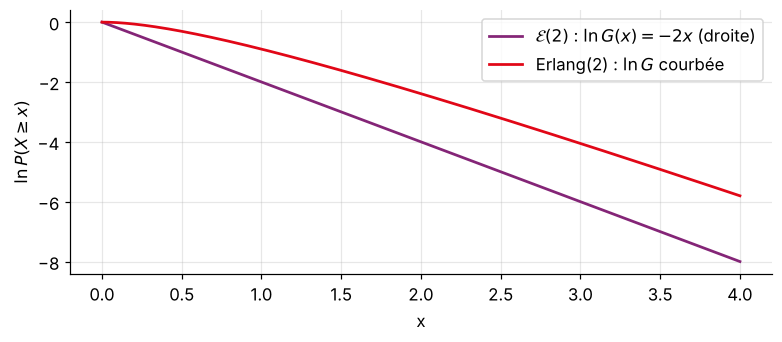

In [9]:
x = np.linspace(0, 4, 300)
lam_f = 2.0
G_exp = np.exp(-lam_f * x)
G_erl = np.exp(-lam_f * x) * (1 + lam_f * x)      # P(T_2 >= x) pour Erlang(2)
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.plot(x, np.log(G_exp), color=VIOLET, lw=1.8, label=r"$\mathcal{E}(2)$ : $\ln G(x) = -2x$ (droite)")
ax.plot(x, np.log(G_erl), color=ROUGE, lw=1.8, label=r"Erlang(2) : $\ln G$ courbée")
ax.set_xlabel("x"); ax.set_ylabel(r"$\ln P(X \geq x)$"); ax.legend(); plt.show()

### 🧮 Calcul
Hypothèses : $X \ge 0$ a une densité, et $G(x) = P(X \ge x) > 0$ pour tout $x \ge 0$.

| Étape | Calcul | Pourquoi on a le droit |
|---|---|---|
| 1. Réécrire $(*)$ | $G(x+t) = G(x)G(t)$ | comme en A.2 (inclusion), en multipliant par $G(x) > 0$ |
| 2. Logarithme | $\varphi = \ln G$ vérifie $\varphi(x+t) = \varphi(x) + \varphi(t)$ | $G > 0$ ; $\ln(ab) = \ln a + \ln b$ |
| 3. Monotonie | $\varphi$ est décroissante | si $x \le y$, $\{X \ge y\} \subset \{X \ge x\}$, donc $G(y) \le G(x)$ |
| 4. Entiers | $\varphi(nx) = n\,\varphi(x)$ | récurrence sur $n$ avec l'étape 2 |
| 5. Rationnels | $\varphi(p/q) = \frac{p}{q}\varphi(1)$ | $\varphi(1) = q\,\varphi(1/q)$ par l'étape 4 |
| 6. Réels | $r \le x \le r'$ rationnels $\Rightarrow r'\varphi(1) \le \varphi(x) \le r\varphi(1)$ | décroissance ; puis $r, r' \to x$ (les rationnels sont denses) |
| 7. Conclusion | $G(x) = e^{-\lambda x}$ avec $\lambda = -\varphi(1)$ | $G = e^\varphi$ |
| 8. $\lambda > 0$ | si $\lambda = 0$, $G \equiv 1$, impossible | $P(X \ge x) \to 0$ quand $x \to \infty$ |

$$\boxed{(*) \text{ pour tous } x, t \ge 0 \iff X \sim \mathcal E(\lambda)}$$

**Version rapide** (si $G$ est dérivable) : dériver $G(x+t) = G(x)G(t)$ en $t = 0$ donne
$G' = G'(0)\,G$, donc $G(x) = e^{G'(0)x}$.

### 🐍 Code
On compare à une loi **avec** mémoire : Erlang(2), somme de deux $\mathcal E(2)$ indépendantes. On
tire $2 \times 10^5$ nouvelles exponentielles (tirages n° 2 et 3 de `rng`, comme dans le rendu), puis on
trace la figure du rendu.

Erlang(2) : P(Y >= x + 0,5 | Y >= x) pour x = 0 ; 0,5 ; 1 : 0.735  0.551  0.487
théorie Erlang(2)                                  : 0.736  0.552  0.491


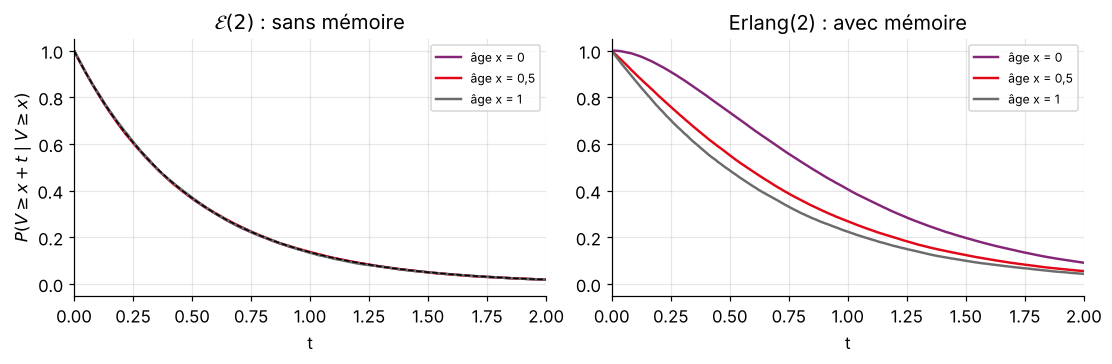

In [10]:
Y = exponentielle_inversion(lam, T, rng) + exponentielle_inversion(lam, T, rng)   # Erlang(2)
reste_erl = [Y[Y >= x] - x for x in ages]
p_erl = [np.mean(R >= t0) for R in reste_erl]
print("Erlang(2) : P(Y >= x + 0,5 | Y >= x) pour x = 0 ; 0,5 ; 1 :", "  ".join(f"{v:.3f}" for v in p_erl))
th = [np.exp(-lam*t0) * (1 + lam*(x + t0)) / (1 + lam*x) for x in ages]   # formule exacte
print("théorie Erlang(2)                                  :", "  ".join(f"{v:.3f}" for v in th))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
tt = np.linspace(0, 2, 200)
for ax, reste, titre in [(axs[0], reste_expo, r"$\mathcal{E}(2)$ : sans mémoire"), (axs[1], reste_erl, "Erlang(2) : avec mémoire")]:
    for x0, R, c in zip(ages, reste, [VIOLET, ROUGE, GRIS]):
        r, Fc = repartition_complementaire(R)
        ax.plot(r, Fc, color=c, lw=1.6, label=virgule(f"âge x = {x0:g}"))
    ax.set_xlim(0, 2); ax.set_title(titre); ax.set_xlabel("t"); ax.legend(fontsize=8)
axs[0].plot(tt, np.exp(-lam * tt), "k--", lw=1)
axs[0].set_ylabel(r"$P(V \geq x + t \mid V \geq x)$"); plt.show()

### 📊 Lecture
Pour Erlang(2), la probabilité de durer encore $0{,}5$ passe de $0{,}735$ (âge 0) à $0{,}551$ (âge
0,5) puis $0{,}487$ (âge 1), en accord avec la formule exacte $e^{-\lambda t}\frac{1 + \lambda(x+t)}{1 + \lambda x}$
($0{,}736$ ; $0{,}552$ ; $0{,}491$) : cette durée « vieillit ». Les courbes de l'exponentielle, elles,
sont confondues. Cela illustre A.3 : on ne peut pas avoir l'absence de mémoire sans être exponentiel.

### ⚠️ Pièges
- Hypothèses oubliées : « à densité » compte. En **discret**, la loi géométrique est aussi sans
  mémoire.
- Dire « par continuité » sans justifier : ici c'est la **monotonie** de $G$ qui permet de passer
  des rationnels aux réels.
- Oublier de montrer que $\lambda > 0$.

### ✋ À toi
Montre (calcul puis simulation) que la loi uniforme $\mathcal U[0,1]$ **n'est pas** sans mémoire :
compare $P(U \ge 0{,}8 \mid U \ge 0{,}5)$ et $P(U \ge 0{,}3)$.

In [11]:
# U = rng_exo.random(100_000)
# print(np.mean(U[U >= 0.5] >= 0.8), np.mean(U >= 0.3))

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

$P(U \ge 0{,}8 \mid U \ge 0{,}5) = 0{,}2/0{,}5 = 0{,}4$ alors que $P(U \ge 0{,}3) = 0{,}7$ : avoir
déjà « duré » $0{,}5$ rapproche de la fin (l'uniforme s'arrête à 1).
```python
U = rng_exo.random(100_000)
print(np.mean(U[U >= 0.5] >= 0.8), np.mean(U >= 0.3))   # ≈ 0,40 et 0,70
```

</details>

### 🗣️ La réponse en 30 secondes
<details>
<summary><b>Ce que je dis au jury</b></summary>

« Si $X$ est sans mémoire, $G(x) = P(X \ge x)$ vérifie $G(x+t) = G(x)G(t)$. Son logarithme est
additif et décroissant ; il est linéaire sur les rationnels, puis sur les réels par monotonie. Donc
$G(x) = e^{-\lambda x}$ : c'est l'exponentielle. Contre-exemple simulé : pour Erlang(2), la
probabilité de durer encore $0{,}5$ passe de $0{,}735$ à $0{,}487$ quand l'âge passe de 0 à 1. »

</details>

### 🎤 Jury
Questions 5 et 6 de [questions_oral.md](questions_oral.md). Piège : « Une ampoule réelle est-elle
sans mémoire ? » (non, elle s'use ; l'exponentielle modélise des pannes à taux constant).

## B.1 · Densité d'une somme : la convolution

### 🎯 Objectif
> *Énoncé.* Soit $X_1$ et $X_2$ deux variables aléatoires à densité et indépendantes de densités
> $f$ et $g$. Montrer que $Z = X_1 + X_2$ a pour densité $f * g$.

**Ce qu'on demande vraiment** : la densité de la somme est $(f*g)(z) = \int f(x)\,g(z - x)\,dx$ :
pour obtenir $z$, il faut $X_1 = x$ et $X_2 = z - x$, et on additionne sur tous les $x$ possibles.

### 💡 Intuition
**$(f*g)(z)$ est l'aire sous le produit $f(x)\,g(z-x)$ : on fait glisser $g$ retournée sur $f$.**
Exemple avec deux uniformes sur $[0, 1]$ : l'aire commune grandit puis diminue, d'où une densité en
triangle.

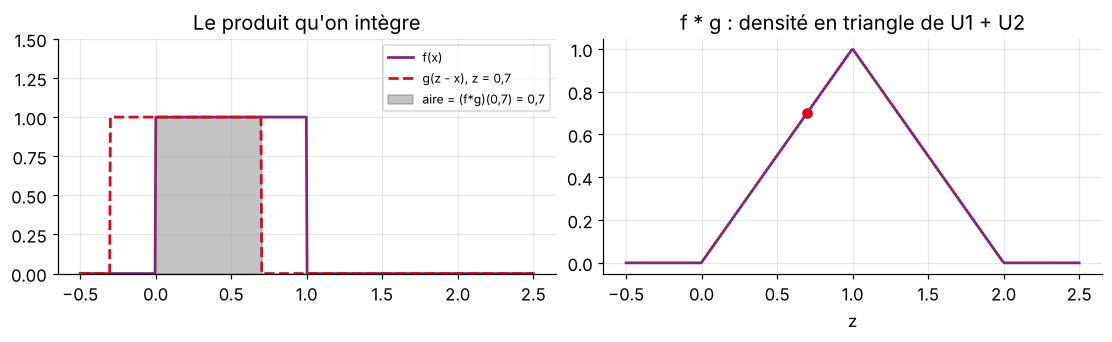

In [12]:
x = np.linspace(-0.5, 2.5, 600)
f = lambda u: ((u >= 0) & (u <= 1)).astype(float)   # densité de U[0, 1]
z0 = 0.7
fig, axs = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
axs[0].plot(x, f(x), color=VIOLET, lw=1.8, label="f(x)")
axs[0].plot(x, f(z0 - x), color=ROUGE, lw=1.8, ls="--", label=r"g(z - x), z = 0,7")
axs[0].fill_between(x, f(x) * f(z0 - x), color=GRIS, alpha=0.4, label="aire = (f*g)(0,7) = 0,7")
axs[0].set_ylim(0, 1.5); axs[0].legend(fontsize=8); axs[0].set_title("Le produit qu'on intègre")
zz = np.linspace(-0.5, 2.5, 400)
conv = np.array([np.trapezoid(f(x) * f(z - x), x) for z in zz])
axs[1].plot(zz, conv, color=VIOLET, lw=1.8); axs[1].plot([z0], [z0], "o", color=ROUGE)
axs[1].set_title("f * g : densité en triangle de U1 + U2"); axs[1].set_xlabel("z")
plt.show()

### 🧮 Calcul
| Étape | Calcul | Pourquoi on a le droit |
|---|---|---|
| 1. Densité du couple | $(x_1, x_2) \mapsto f(x_1)g(x_2)$ | **indépendance** |
| 2. Répartition de $Z$ | $P(Z \le z) = \iint_{x_1 + x_2 \le z} f(x_1)g(x_2)\,dx_1dx_2$ | probabilité d'une région = intégrale de la densité |
| 3. Intégrer en $x_2$ d'abord | $= \int f(x_1)\int_{-\infty}^{z - x_1} g(x_2)\,dx_2\,dx_1$ | $x_2 \le z - x_1$ |
| 4. Changement de variable | $x_2 = s - x_1$ : $\int_{-\infty}^{z} g(s - x_1)\,ds$ | $x_1$ fixé, jacobien 1 |
| 5. Échanger | $P(Z \le z) = \int_{-\infty}^z \Big(\int f(x_1)g(s - x_1)dx_1\Big) ds$ | **Fubini-Tonelli** (fonction positive) |
| 6. Conclure | la répartition est l'intégrale de $f*g$, donc $f_Z = f * g$ | densité = fonction qu'on intègre pour avoir $F$ |

$$\boxed{f_{X_1 + X_2}(z) = \int_{\mathbb R} f(x)\,g(z - x)\,dx}$$

### 🐍 Code
Contrôle numérique sans hasard : on calcule $f * f$ pour $f$ la densité de $\mathcal E(2)$ par une
intégrale numérique (`np.trapezoid`) et on la compare à la formule de B.2, $\lambda^2 x e^{-\lambda x}$.

In [13]:
f_exp = lambda u: np.where(u >= 0, lam * np.exp(-lam * np.clip(u, 0, None)), 0.0)
grille = np.linspace(-1, 8, 20_001)
for z in (0.25, 0.5, 1.0, 2.0):
    num = np.trapezoid(f_exp(grille) * f_exp(z - grille), grille)
    print(f"z = {z}: (f*f)(z) numérique = {num:.5f}   formule λ² z e^(-λz) = {lam**2 * z * np.exp(-lam*z):.5f}")

z = 0.25: (f*f)(z) numérique = 0.60592   formule λ² z e^(-λz) = 0.60653
z = 0.5: (f*f)(z) numérique = 0.73569   formule λ² z e^(-λz) = 0.73576
z = 1.0: (f*f)(z) numérique = 0.54129   formule λ² z e^(-λz) = 0.54134
z = 2.0: (f*f)(z) numérique = 0.14651   formule λ² z e^(-λz) = 0.14653


### 📊 Lecture
Les deux colonnes coïncident à moins de $10^{-3}$ près (erreur de l'intégration numérique, la plus grande en $z = 0{,}25$ où la densité varie vite) : la convolution
de deux $\mathcal E(2)$ donne bien la densité d'Erlang $f_2$, ce qu'on démontre en B.2.

### ⚠️ Pièges
- Oublier l'**indépendance** : sans elle, la densité du couple n'est pas le produit.
- Mal placer les bornes : pour deux densités nulles sur $\mathbb R^-$, l'intégrale va de 0 à $z$.
- Confondre convolution ($f * g$) et produit ($f \cdot g$).

### ✋ À toi
Avec la formule, calcule la densité de $U_1 + U_2$ ($U_i \sim \mathcal U[0,1]$ indépendantes) en
$z = 1{,}5$. Vérifie avec un histogramme (`rng_exo`).

In [14]:
# S = rng_exo.random(200_000) + rng_exo.random(200_000)
# densité près de 1,5 : np.mean(np.abs(S - 1.5) < 0.01) / 0.02

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

$(f*g)(1{,}5) = \int_0^1 \mathbb 1_{0 \le 1{,}5 - x \le 1}dx = \int_{0{,}5}^1 dx = 0{,}5$ (triangle :
$2 - z$ pour $z \in [1, 2]$).
```python
S = rng_exo.random(200_000) + rng_exo.random(200_000)
print(np.mean(np.abs(S - 1.5) < 0.01) / 0.02)   # ≈ 0,5
```

</details>

### 🗣️ La réponse en 30 secondes
<details>
<summary><b>Ce que je dis au jury</b></summary>

« Comme $X_1$ et $X_2$ sont indépendantes, la densité du couple est le produit $f(x_1)g(x_2)$. On
intègre sur la région $x_1 + x_2 \le z$, on pose $s = x_1 + x_2$ et on échange les intégrales par
Fubini : la fonction de répartition de $Z$ est l'intégrale de $\int f(x)g(s - x)dx$, donc la densité
de $Z$ est $f * g$. »

</details>

### 🎤 Jury
Questions 7 et 8 de [questions_oral.md](questions_oral.md). Piège : « Où utilisez-vous
l'indépendance ? » (pour écrire la densité du couple comme un produit).

## B.2 · Les instants $T_k$ suivent des lois d'Erlang

### 🎯 Objectif
> *Énoncé.* $I_n$ = temps entre deux événements, $T_n = \sum_{k=1}^n I_k$ l'instant du $n$-ième
> événement, $I_1 \sim \mathcal E(\lambda)$. Montrer que $T_2$ a la densité $\lambda^2 x e^{-\lambda x}$,
> puis par récurrence que $T_k$ a la densité $f_k(x) = \frac{\lambda^k x^{k-1}}{(k-1)!}e^{-\lambda x}$.

**Ce qu'on demande vraiment** : l'instant du $k$-ième événement est une somme de $k$ exponentielles
indépendantes ; on calcule sa densité par convolutions successives (B.1).

**Coquille d'indice** : avec $T_n = I_1 + \dots + I_n$, $I_n$ sépare le $(n-1)$-ième et le $n$-ième
événement (l'origine $t = 0$ compte comme « événement 0 », $T_0 = 0$).

### 💡 Intuition
**Un processus de Poisson, ce sont des points posés sur l'axe du temps avec des écarts
exponentiels indépendants ; $T_k$ est la position du $k$-ième point.**

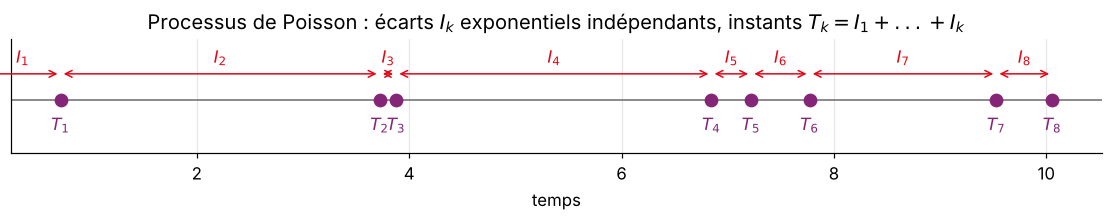

In [15]:
ecarts = exponentielle_inversion(1.0, 8, rng_fig)       # λ = 1, générateur des figures
Tf = np.cumsum(ecarts)
fig, ax = plt.subplots(figsize=(10, 1.9), layout="constrained")
ax.axhline(0, color=GRIS, lw=1)
ax.plot(Tf, np.zeros_like(Tf), "o", color=VIOLET, ms=8)
prec = 0.0
for k, t_k in enumerate(Tf, start=1):
    ax.annotate("", xy=(t_k, 0.3), xytext=(prec, 0.3), arrowprops=dict(arrowstyle="<->", color=ROUGE))
    ax.text((prec + t_k) / 2, 0.42, f"$I_{k}$", ha="center", color=ROUGE)
    ax.text(t_k, -0.35, f"$T_{k}$", ha="center", color=VIOLET)
    prec = t_k
ax.set_ylim(-0.6, 0.7); ax.set_yticks([]); ax.set_xlabel("temps")
ax.set_title("Processus de Poisson : écarts $I_k$ exponentiels indépendants, instants $T_k = I_1 + ... + I_k$")
plt.show()

### 🧮 Calcul
| Étape | Calcul | Pourquoi on a le droit |
|---|---|---|
| 1. $T_2$ par B.1 | $f_2(x) = \int \lambda e^{-\lambda u}\mathbb 1_{u \ge 0}\ \lambda e^{-\lambda(x-u)}\mathbb 1_{x-u \ge 0}\,du$ | $I_1, I_2$ indépendantes de densité $\lambda e^{-\lambda u}\mathbb 1_{u \ge 0}$ |
| 2. Bornes | les indicatrices imposent $0 \le u \le x$ | sinon le produit est nul |
| 3. Simplifier | $e^{-\lambda u}e^{-\lambda(x-u)} = e^{-\lambda x}$, donc $f_2(x) = \lambda^2 e^{-\lambda x}\int_0^x du = \lambda^2 x e^{-\lambda x}$ | ne dépend plus de $u$ |
| 4. Hypothèse de récurrence | $T_k$ a la densité $f_k$ | initialisation : $f_1 = \lambda e^{-\lambda x}$ |
| 5. Hérédité | $T_{k+1} = T_k + I_{k+1}$ avec $I_{k+1}$ **indépendant** de $T_k$ | $T_k$ ne dépend que de $I_1, \dots, I_k$ |
| 6. Convolution | $f_{k+1}(x) = \int_0^x \frac{\lambda^k u^{k-1}}{(k-1)!}e^{-\lambda u}\lambda e^{-\lambda(x-u)}du = \lambda^{k+1}e^{-\lambda x}\frac{x^k}{k!}$ | B.1, puis $\int_0^x \frac{u^{k-1}}{(k-1)!}du = \frac{x^k}{k!}$ |

$$\boxed{f_k(x) = \frac{\lambda^k x^{k-1}}{(k-1)!}e^{-\lambda x},\ x \ge 0}$$

**Contrôle** : $E[T_k] = k/\lambda$ (somme de $k$ moyennes $1/\lambda$) et $\int_0^\infty f_k = 1$.

### 🐍 Code
On tire une matrice $T \times k_{\max}$ d'exponentielles (une ligne = une réalisation de
$I_1, \dots, I_5$) et on fait les sommes cumulées le long des lignes : la colonne $k$ contient $T_k$.
(Tirage n° 4 de `rng`, comme dans le rendu.)

T_1 : moyenne 0.4988 (k/λ = 0.5)   KS contre Erlang : p = 0.99
T_2 : moyenne 1.0011 (k/λ = 1.0)   KS contre Erlang : p = 0.99
T_5 : moyenne 2.4971 (k/λ = 2.5)   KS contre Erlang : p = 0.64


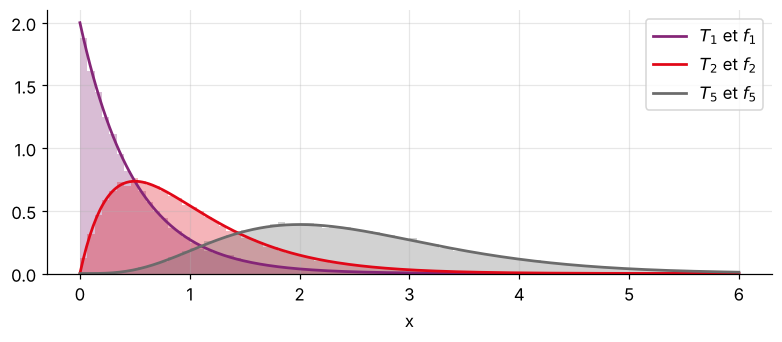

In [16]:
lamB, TB, kmax = 2.0, 50_000, 5
I = exponentielle_inversion(lamB, TB * kmax, rng).reshape(TB, kmax)
Tk = np.cumsum(I, axis=1)                        # colonne k-1 : instant du k-ième événement
f = lambda k, x: lamB**k * x**(k - 1) / factorial(k - 1) * np.exp(-lamB * x)   # densité d'Erlang f_k
for k in (1, 2, 5):
    p_ks = stats.kstest(Tk[:, k - 1], "gamma", args=(k, 0, 1 / lamB)).pvalue
    print(f"T_{k} : moyenne {Tk[:, k-1].mean():.4f} (k/λ = {k/lamB})   KS contre Erlang : p = {p_ks:.2f}")

xg = np.linspace(0, 6, 400)
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
for k, c in zip((1, 2, 5), (VIOLET, ROUGE, GRIS)):
    ax.hist(Tk[:, k - 1], bins=90, range=(0, 6), density=True, color=c, alpha=0.3)
    ax.plot(xg, f(k, xg), color=c, lw=1.8, label=rf"$T_{k}$ et $f_{k}$")
ax.legend(); ax.set_xlabel("x"); plt.show()

### 📊 Lecture
Moyennes $0{,}499$ ; $1{,}001$ ; $2{,}497$ pour $k/\lambda = 0{,}5$ ; $1$ ; $2{,}5$, et tests KS
$p = 0{,}99$ ; $0{,}99$ ; $0{,}64$ : les histogrammes collent aux densités. Plus $k$ est grand, plus
la loi s'étale et ressemble à une gaussienne (théorème central limite : $T_k$ est une somme de $k$
variables indépendantes).

### ⚠️ Pièges
- Intégrer sur $[0, +\infty[$ au lieu de $[0, x]$ : on oublie que $I_2 = x - u \ge 0$.
- Oublier de justifier l'indépendance de $I_{k+1}$ et $T_k$.
- La coquille d'indice : dire quelle convention on prend ($T_0 = 0$).

### ✋ À toi
Pour $\lambda = 2$, donne $E[T_3]$ et $\operatorname{Var}T_3$, puis vérifie avec `rng_exo`.

In [17]:
# T3 = exponentielle_inversion(2.0, 3 * 100_000, rng_exo).reshape(100_000, 3).sum(axis=1)
# print(T3.mean(), T3.var(ddof=1))

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

$E[T_3] = 3/2 = 1{,}5$, $\operatorname{Var}T_3 = 3/4 = 0{,}75$ (variances qui s'ajoutent grâce à
l'indépendance).
```python
T3 = exponentielle_inversion(2.0, 3 * 100_000, rng_exo).reshape(100_000, 3).sum(axis=1)
print(T3.mean(), T3.var(ddof=1))   # ≈ 1,5 et 0,75
```

</details>

### 🗣️ La réponse en 30 secondes
<details>
<summary><b>Ce que je dis au jury</b></summary>

« $T_2 = I_1 + I_2$ avec deux exponentielles indépendantes, donc sa densité est la convolution :
$\int_0^x \lambda e^{-\lambda u}\lambda e^{-\lambda(x-u)}du = \lambda^2 x e^{-\lambda x}$. Par
récurrence, $T_{k+1} = T_k + I_{k+1}$ avec $I_{k+1}$ indépendant de $T_k$, et la même convolution
donne $f_{k+1}$. Les simulations de $T_1$, $T_2$, $T_5$ suivent ces densités. »

</details>

### 🎤 Jury
Question 9 de [questions_oral.md](questions_oral.md). Piège : « Pourquoi l'intégrale s'arrête-t-elle
à $x$ ? » (indicatrice $\mathbb 1_{x - u \ge 0}$).

## B.3 · Le nombre d'événements suit une loi de Poisson

### 🎯 Objectif
> *Énoncé.* $N_t$ = nombre d'événements dans $[0, t]$. Déduire de B.2 que
> $P(N_t = k) = e^{-\lambda t}\frac{(\lambda t)^k}{k!}$. Indication :
> $\{N_t = k\} = \{T_k \le t < T_{k+1}\}$.

**Ce qu'on demande vraiment** : passer des **instants** ($T_k$, Erlang) au **nombre** de points dans
une fenêtre ($N_t$, Poisson). C'est ce qui justifie le nom « processus de Poisson ».

### 💡 Intuition
**$N_t = k$ veut dire : le $k$-ième point est dans la fenêtre, le suivant est dehors.** Plus la
fenêtre est longue ($\lambda t$ grand), plus on compte de points, et plus le nombre est étalé.

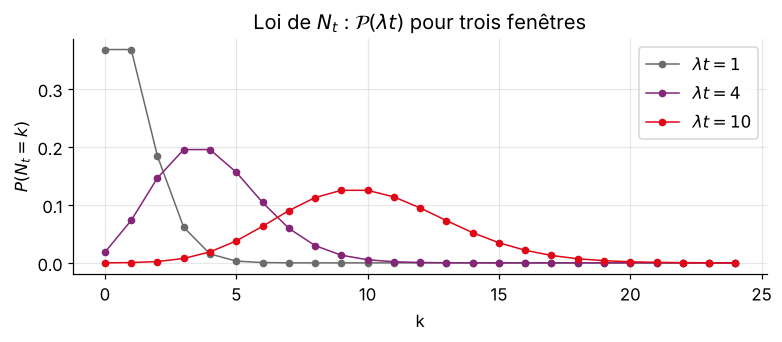

In [18]:
k = np.arange(0, 25)
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
for m, c in [(1, GRIS), (4, VIOLET), (10, ROUGE)]:
    ax.plot(k, stats.poisson.pmf(k, m), "o-", color=c, ms=4, lw=1, label=rf"$\lambda t = {m}$")
ax.set_xlabel("k"); ax.set_ylabel(r"$P(N_t = k)$"); ax.legend()
ax.set_title(r"Loi de $N_t$ : $\mathcal{P}(\lambda t)$ pour trois fenêtres"); plt.show()

### 🧮 Calcul
| Étape | Calcul | Pourquoi on a le droit |
|---|---|---|
| 1. Traduire | $\{N_t = k\} = \{T_k \le t < T_{k+1}\}$ | $k$ points dans $[0, t]$ : le $k$-ième au plus tard en $t$, le suivant après |
| 2. Inclusion | $\{T_{k+1} \le t\} \subset \{T_k \le t\}$ | $T_{k+1} \ge T_k$ |
| 3. Différence | $P(N_t = k) = P(T_k \le t) - P(T_{k+1} \le t) = F_k(t) - F_{k+1}(t)$ | $P(A \setminus B) = P(A) - P(B)$ si $B \subset A$ |
| 4. IPP sur $F_{k+1}$ | $F_{k+1}(t) = \Big[-\frac{(\lambda u)^k}{k!}e^{-\lambda u}\Big]_0^t + \int_0^t \frac{\lambda^k u^{k-1}}{(k-1)!}e^{-\lambda u}du$ | $U = \frac{(\lambda u)^k}{k!}$, $V' = \lambda e^{-\lambda u}$ ($k \ge 1$) |
| 5. Reconnaître | $F_{k+1}(t) = -e^{-\lambda t}\frac{(\lambda t)^k}{k!} + F_k(t)$ | la dernière intégrale est $F_k(t)$ |
| 6. Cas $k = 0$ | $P(N_t = 0) = P(T_1 > t) = e^{-\lambda t}$ | $T_1 \sim \mathcal E(\lambda)$ |

$$\boxed{P(N_t = k) = e^{-\lambda t}\frac{(\lambda t)^k}{k!}:\quad N_t \sim \mathcal P(\lambda t)}$$

**Contrôle** : $E[N_t] = \lambda t$, c'est bien « $\lambda$ événements par unité de temps ».

### 🐍 Code
Vérification **sans hasard** de l'étape 3 : avec les fonctions de répartition d'Erlang de `scipy`
(loi gamma), on calcule $F_k(t) - F_{k+1}(t)$ et on compare à la formule de Poisson. (La vérification
par simulation, $N_3$ avec $\lambda = 2$, est faite en S.2 pour garder l'ordre des tirages du rendu.)

In [19]:
lamt, tt3 = 2.0, 3.0
for k in (0, 2, 6, 10):
    Fk = stats.gamma.cdf(tt3, k, scale=1/lamt) if k > 0 else 1.0     # F_0 = 1 (T_0 = 0)
    Fk1 = stats.gamma.cdf(tt3, k + 1, scale=1/lamt)
    print(f"k = {k:2d}: F_k(t) - F_k+1(t) = {Fk - Fk1:.6f}   e^(-λt)(λt)^k/k! = {stats.poisson.pmf(k, lamt*tt3):.6f}")

k =  0: F_k(t) - F_k+1(t) = 0.002479   e^(-λt)(λt)^k/k! = 0.002479
k =  2: F_k(t) - F_k+1(t) = 0.044618   e^(-λt)(λt)^k/k! = 0.044618
k =  6: F_k(t) - F_k+1(t) = 0.160623   e^(-λt)(λt)^k/k! = 0.160623
k = 10: F_k(t) - F_k+1(t) = 0.041303   e^(-λt)(λt)^k/k! = 0.041303


### 📊 Lecture
Les deux colonnes sont identiques (à $10^{-6}$ près) pour $\lambda t = 6$ : l'identité
$P(N_t = k) = F_k(t) - F_{k+1}(t)$ et le calcul par IPP sont confirmés.

### ⚠️ Pièges
- Écrire $P(T_k \le t)\,P(T_{k+1} > t)$ : faux, les deux événements ne sont **pas** indépendants
  ($T_{k+1} = T_k + I_{k+1}$).
- Oublier le cas $k = 0$ (l'IPP demande $k \ge 1$).
- Oublier que $\{T_{k+1} \le t\} \subset \{T_k \le t\}$, qui justifie la soustraction.

### ✋ À toi
Des appels arrivent selon un processus de Poisson de 3 par minute. Calcule $P(N_2 = 0)$ et
$P(N_2 = 6)$ (sur 2 minutes), puis vérifie avec `poisson_comptage` et `rng_exo`.

In [20]:
# N2 = poisson_comptage(3.0, 50_000, rng_exo, duree=2.0)
# print(np.mean(N2 == 0), np.mean(N2 == 6))

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

$\lambda t = 6$ : $P(N_2 = 0) = e^{-6} \approx 0{,}0025$, $P(N_2 = 6) = e^{-6}6^6/720 \approx 0{,}1606$.
```python
N2 = poisson_comptage(3.0, 50_000, rng_exo, duree=2.0)
print(np.mean(N2 == 0), np.mean(N2 == 6))
```

</details>

### 🗣️ La réponse en 30 secondes
<details>
<summary><b>Ce que je dis au jury</b></summary>

« Il y a $k$ événements dans $[0, t]$ exactement quand $T_k \le t < T_{k+1}$. Comme
$\{T_{k+1} \le t\}$ est inclus dans $\{T_k \le t\}$, la probabilité vaut $F_k(t) - F_{k+1}(t)$. Une
intégration par parties sur $F_{k+1}$ fait apparaître $F_k$ et le terme $e^{-\lambda t}(\lambda t)^k/k!$ :
$N_t$ suit la loi de Poisson de paramètre $\lambda t$. »

</details>

### 🎤 Jury
Question 10 de [questions_oral.md](questions_oral.md). Piège : « Pourquoi pas un produit de
probabilités ? » (pas d'indépendance entre $T_k$ et $T_{k+1}$).

## S.1 · Simuler $\mathcal E(\lambda)$ : $X = -\frac{1}{\lambda}\ln U$

### 🎯 Objectif
> *Énoncé.* Montrer que si $U \sim \mathcal U[0,1]$ alors $X = -\frac{1}{\lambda}\log U$ est
> $\mathcal E(\lambda)$.

**Ce qu'on demande vraiment** : transformer un nombre au hasard dans $[0, 1]$ en une durée
exponentielle. C'est la **méthode d'inversion** du sujet 1.

### 💡 Intuition
**La fonction $u \mapsto -\ln(u)/\lambda$ envoie les $u$ proches de 1 vers des durées courtes et les
$u$ proches de 0 vers des durées longues** : comme les $u$ sont répartis uniformément, on obtient
beaucoup de petites valeurs et quelques grandes, exactement la forme exponentielle.

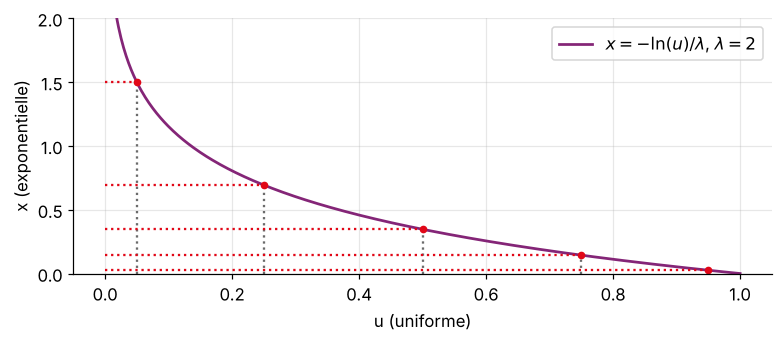

In [21]:
u = np.linspace(0.001, 1, 500)
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.plot(u, -np.log(u) / 2, color=VIOLET, lw=1.8, label=r"$x = -\ln(u)/\lambda$, $\lambda = 2$")
for u0 in (0.05, 0.25, 0.5, 0.75, 0.95):
    x0 = -np.log(u0) / 2
    ax.plot([u0, u0], [0, x0], ":", color=GRIS); ax.plot([0, u0], [x0, x0], ":", color=ROUGE)
    ax.plot(u0, x0, "o", color=ROUGE, ms=4)
ax.set_xlabel("u (uniforme)"); ax.set_ylabel("x (exponentielle)"); ax.set_ylim(0, 2); ax.legend()
plt.show()

### 🧮 Calcul
| Étape | Calcul | Pourquoi on a le droit |
|---|---|---|
| 1. Signe | $U \in\, ]0, 1]$ donc $\ln U \le 0$ et $X \ge 0$ | $\ln$ négatif sur $]0, 1]$ |
| 2. $x < 0$ | $P(X \ge x) = 1$ | $X \ge 0$ toujours |
| 3. $x \ge 0$ | $P(-\frac1\lambda \ln U \ge x) = P(\ln U \le -\lambda x)$ | on multiplie par $-\lambda < 0$ : l'inégalité change de sens |
| 4. Exponentielle | $= P(U \le e^{-\lambda x})$ | $\exp$ est **croissante** |
| 5. Uniforme | $= e^{-\lambda x}$ | $P(U \le u) = u$ pour $u = e^{-\lambda x} \in\, ]0, 1]$ |

$$\boxed{U \sim \mathcal U[0,1] \Rightarrow -\tfrac{1}{\lambda}\ln U \sim \mathcal E(\lambda)}$$

**Lien avec l'inversion** : $F(x) = 1 - e^{-\lambda x}$ donne $F^{-1}(v) = -\frac1\lambda\ln(1 - v)$ ;
et $1 - U$ a même loi que $U$.

### 🐍 Code
Le code utilise $1 - U$ plutôt que $U$ : `rng.random()` peut renvoyer 0 (valeurs dans $[0, 1[$), et
$\ln 0 = -\infty$. Fonction réutilisée partout (A, B, file) : `exponentielle_inversion`, et sa version
« un seul tirage » `_expo` de `files_attente.py`. On réutilise les $X$ de A.1.

In [22]:
from stats_td import files_attente
print(inspect.getsource(files_attente._expo))
print(f"les X de A.1 : min {X.min():.2e}, max {X.max():.2f}, moyenne {X.mean():.4f}")

def _expo(lam, rng):
    """Un tirage de E(lam) par inversion : -ln(1 - U) / lam (1 - U évite ln 0)."""
    return -np.log(1.0 - rng.random()) / lam

les X de A.1 : min 3.79e-06, max 6.21, moyenne 0.4976


### 📊 Lecture
Les $X$ simulés en A.1 sont tous positifs, de moyenne $0{,}498$, et passent le test KS
($p = 0{,}15$) : la méthode d'inversion fonctionne. Le maximum (environ 6) est rare mais normal :
$P(X \ge 6) = e^{-12} \approx 6 \times 10^{-6}$, et on a $10^5$ tirages.

### ⚠️ Pièges
- $\ln U$ est négatif : sans le signe moins, on obtient des durées négatives.
- `log` en Matlab et `np.log` en Python sont des logarithmes **népériens** (pas en base 10).
- $\ln 0$ : utiliser $1 - U$.

### ✋ À toi
Simule $10^5$ valeurs de $\mathcal E(5)$ **à la main** (sans la fonction) avec `rng_exo` et vérifie
que la moyenne vaut environ $0{,}2$.

In [23]:
# U = rng_exo.random(100_000)
# X5 = -np.log(1 - U) / 5 ; print(X5.mean())

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

```python
U = rng_exo.random(100_000)
X5 = -np.log(1 - U) / 5
print(X5.mean(), X5.std(ddof=1))   # ≈ 0,2 et 0,2 (moyenne = écart-type, A.1)
```

</details>

### 🗣️ La réponse en 30 secondes
<details>
<summary><b>Ce que je dis au jury</b></summary>

« Pour $x \ge 0$, $P(-\ln U/\lambda \ge x) = P(U \le e^{-\lambda x})$ car l'exponentielle est
croissante, et ça vaut $e^{-\lambda x}$ car $U$ est uniforme. C'est la méthode d'inversion. Dans le
code j'utilise $1 - U$, de même loi, pour ne jamais calculer $\ln 0$. »

</details>

### 🎤 Jury
Question 11 de [questions_oral.md](questions_oral.md). Piège : « Pourquoi $1 - U$ ? »
(`rng.random()` peut valoir 0).

## S.2 · Simuler $\mathcal P(\lambda)$ en comptant des exponentielles

### 🎯 Objectif
> *Énoncé.* Si $(X_i)$ sont indépendantes de loi $\mathcal E(\lambda)$ et $Z_i = X_1 + \dots + X_i$,
> alors $N = \sum_{i \ge 1}\mathbb 1_{Z_i \le 1}$ suit $\mathcal P(\lambda)$. En déduire un algorithme.

**Ce qu'on demande vraiment** : les $Z_i$ sont les instants d'un processus de Poisson ; compter
ceux qui tombent dans $[0, 1]$, c'est $N_1$, de loi $\mathcal P(\lambda)$ par B.3 (égalité **en loi**).

### 💡 Intuition
**On empile des durées exponentielles jusqu'à dépasser 1 ; le nombre de marches sous la ligne est
$N$.** Chaque escalier ci-dessous est un tirage ($\lambda = 4$).

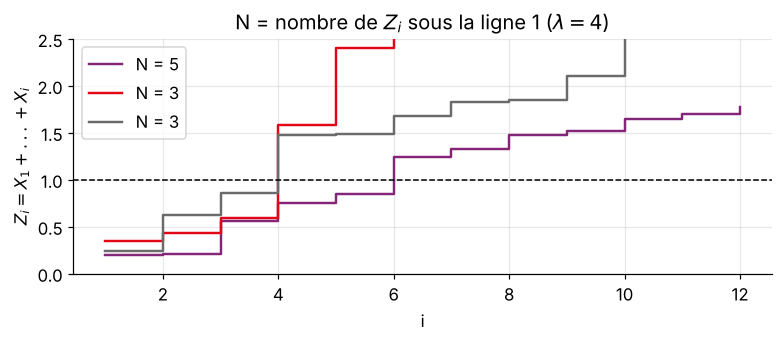

In [24]:
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
for c in (VIOLET, ROUGE, GRIS):
    Z = np.cumsum(exponentielle_inversion(4.0, 12, rng_fig))
    n = int(np.sum(Z <= 1))
    ax.step(np.arange(1, 13), Z, where="post", color=c, lw=1.6, label=f"N = {n}")
ax.axhline(1, color="k", ls="--", lw=1)
ax.set_ylim(0, 2.5); ax.set_xlabel("i"); ax.set_ylabel(r"$Z_i = X_1 + ... + X_i$")
ax.set_title(r"N = nombre de $Z_i$ sous la ligne 1 ($\lambda = 4$)"); ax.legend(); plt.show()

### 🧮 Calcul
| Étape | Calcul / algorithme | Pourquoi on a le droit |
|---|---|---|
| 1. Reconnaître | les $Z_i$ sont les instants $T_i$ d'un processus de Poisson d'intensité $\lambda$ | écarts $X_i$ indépendants $\mathcal E(\lambda)$ : définition (B) |
| 2. Compter | $\sum_i \mathbb 1_{Z_i \le 1} = N_1$ | nombre de points dans $[0, 1]$ |
| 3. Loi | $N_1 \sim \mathcal P(\lambda \cdot 1)$ | B.3 avec $t = 1$ |
| 4. Algorithme | $N \leftarrow 0$, $Z \leftarrow \mathcal E(\lambda)$ ; tant que $Z \le 1$ : $N \leftarrow N + 1$, $Z \leftarrow Z + \mathcal E(\lambda)$ | S.1 pour chaque $\mathcal E(\lambda)$ |
| 5. Coût | $N + 1$ uniformes, $\lambda + 1$ en moyenne | $E[N] = \lambda$ |

**Variante (Knuth)** : $Z_i \le 1 \iff U_1 \cdots U_i \ge e^{-\lambda}$ (on prend $\exp$ de
$-\lambda Z_i$) : on multiplie des uniformes, sans logarithme.

**Pour un paramètre $\mu s$** : on compte les sommes de $\mathcal E(\mu)$ qui restent $\le s$
(c'est ce que fait la file pour $A_n$).

### 🐍 Code
La fonction `nombre_points_poisson(lam, duree, rng)` fait exactement l'algorithme, sur $[0, \text{durée}]$ ;
`poisson_comptage` la répète $T$ fois. Puis on tire $5 \times 10^4$ valeurs de $\mathcal P(4)$ et
$2 \times 10^4$ valeurs de $N_3$ pour $\lambda = 2$ (tirages n° 5 et 6 de `rng`, comme dans le rendu).

def nombre_points_poisson(lam, duree, rng):
    """Nombre de points d'un processus de Poisson d'intensité lam dans [0, duree].

    On additionne des durées E(lam) tant que la somme Z_i reste <= duree :
    N = sum_i 1{Z_i <= duree}, de loi P(lam * duree) (sujet 4, B.3 et
    simulation Q2). Coût moyen : lam * duree + 1 uniformes.
    """
    if lam <= 0:
        raise ValueError("lambda doit être strictement positif")
    if duree < 0:
        raise ValueError("la durée doit être positive")
    n = 0
    Z = _expo(lam, rng)
    while Z <= duree:
        n += 1
        Z += _expo(lam, rng)
    return n

def poisson_comptage(lam, T, rng, duree=1.0):
    """T tirages indépendants de P(lam * duree) par comptage d'exponentielles.

    Avec duree = 1 : algorithme de l'énoncé, N = sum_{i>=1} 1{Z_i <= 1}.
    """
    return np.array([nombre_points_poisson(lam, duree, rng) for _ in range(T)], dtype=np.int64)



P(4) par comptage : moyenne 3.9876, variance 3.9640   chi2 : p = 0.37


N_3 (λ = 2) : moyenne 5.9948, variance 6.0798 (théorie λt = 6)


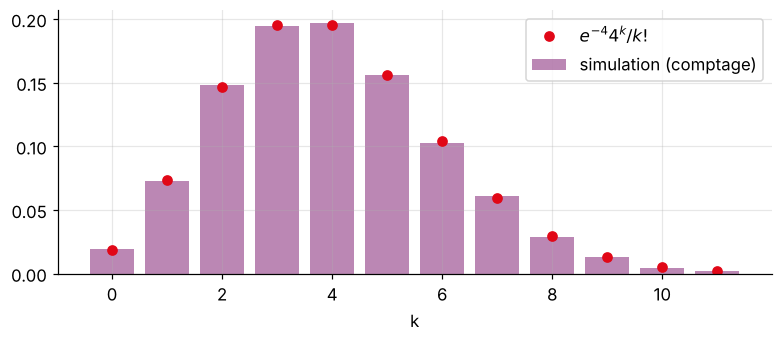

In [25]:
print(inspect.getsource(nombre_points_poisson))
print(inspect.getsource(poisson_comptage))

lamP, TP = 4.0, 50_000
N = poisson_comptage(lamP, TP, rng)
kk = np.arange(0, 13)
obs = np.array([(N == k).sum() for k in kk[:-1]] + [(N >= kk[-1]).sum()])
th = np.append(stats.poisson.pmf(kk[:-1], lamP), stats.poisson.sf(kk[-1] - 1, lamP))
print(f"P(4) par comptage : moyenne {N.mean():.4f}, variance {N.var(ddof=1):.4f}   chi2 : p = {stats.chisquare(obs, TP * th).pvalue:.2f}")
N3 = poisson_comptage(2.0, 20_000, rng, duree=3.0)        # B.3 : N_t sur [0, 3], λ = 2
print(f"N_3 (λ = 2) : moyenne {N3.mean():.4f}, variance {N3.var(ddof=1):.4f} (théorie λt = 6)")

fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.bar(kk[:-1], obs[:-1] / TP, color=VIOLET, alpha=0.55, label="simulation (comptage)")
ax.plot(kk[:-1], th[:-1], "o", color=ROUGE, label=r"$e^{-4}4^k/k!$"); ax.legend(); ax.set_xlabel("k")
plt.show()

### 📊 Lecture
Moyenne $3{,}99$ et variance $3{,}96$ pour $\mathcal P(4)$ (les deux valent 4 en théorie), et le test du
$\chi^2$ sur toute la loi donne $p = 0{,}37$ : rien d'anormal. Pour B.3 : $N_3$ avec $\lambda = 2$ a pour
moyenne $5{,}99$ et variance $6{,}08$, pour $\lambda t = 6$. L'algorithme simule bien la loi de Poisson,
et confirme B.3 par simulation.

### ⚠️ Pièges
- C'est une égalité **en loi** : la somme a la loi de $N$, elle n'est pas « égale » à une variable $N$ donnée.
- Compter aussi le premier $Z$ qui dépasse 1 (erreur d'une unité : on obtiendrait $N + 1$).
- Coût : pour $\lambda = 10^4$, l'algorithme tire $10^4$ uniformes par valeur : trop lent.

### ✋ À toi
Programme la variante de Knuth (produit d'uniformes) pour $\lambda = 4$, tire $5 \times 10^4$ valeurs
avec `rng_exo` et compare la moyenne à 4.

In [26]:
# def poisson_knuth(lam, rng):
#     seuil, n, p = np.exp(-lam), 0, rng.random()
#     ...  # tant que p >= seuil : n += 1 ; p *= rng.random()
# print(np.mean([poisson_knuth(4.0, rng_exo) for _ in range(50_000)]))

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

```python
def poisson_knuth(lam, rng):
    seuil, n, p = np.exp(-lam), 0, rng.random()
    while p >= seuil:          # U_1 ... U_{n+1} >= e^{-λ}  <=>  Z_{n+1} <= 1
        n += 1
        p *= rng.random()
    return n
print(np.mean([poisson_knuth(4.0, rng_exo) for _ in range(50_000)]))   # ≈ 4
```
(On utilise $U$ au lieu de $1 - U$ : ici $U = 0$ ferait juste un produit nul, sans erreur.)

</details>

### 🗣️ La réponse en 30 secondes
<details>
<summary><b>Ce que je dis au jury</b></summary>

« Les sommes $Z_i$ de durées exponentielles sont les instants d'un processus de Poisson ; en compter
le nombre dans $[0, 1]$ donne une loi de Poisson de paramètre $\lambda$, par la question B.3.
L'algorithme ajoute donc des $\mathcal E(\lambda)$ jusqu'à dépasser 1 et compte. Il coûte $\lambda + 1$
uniformes en moyenne. J'obtiens moyenne $3{,}99$ et variance $3{,}96$ pour $\lambda = 4$. »

</details>

### 🎤 Jury
Questions 12 et 13 de [questions_oral.md](questions_oral.md). Piège : « Et si $\lambda$ est très
grand ? » (coût en $\lambda$ ; autre méthode, question bonus).

## Q1 · La récurrence $L_{n+1} = (L_n + 1 - A_n)^+$

### 🎯 Objectif
> *Énoncé.* $N(t)$ processus de Poisson d'intensité $\mu$, $L_n = L(T_n^-)$ la longueur juste avant
> le $n$-ième client. Montrer que $L_{n+1} = (L_n + 1 - A_n)^+ = \max(0, L_n + 1 - A_n)$ où
> $A_n = N(T_{n+1}) - N(T_n)$ est distribuée comme le nombre de clients qui seraient servis dans
> $[T_n, T_{n+1}[$ si la file ne se vidait pas.

**Ce qu'on demande vraiment** : écrire comment la file évolue d'une arrivée à la suivante. $L$ compte
**tous** les clients présents (en attente + en service). $T_n^-$ veut dire « juste avant $T_n$ ».

### 💡 Intuition
**Entre deux arrivées, on retire $A_n$ clients au total déjà présent ($L_n + 1$), sans jamais
descendre sous 0.** La fonction $l \mapsto \max(0, l + 1 - a)$ est une « crosse de hockey » : plate à 0
tant que les services possibles suffisent à vider la file, puis une droite.

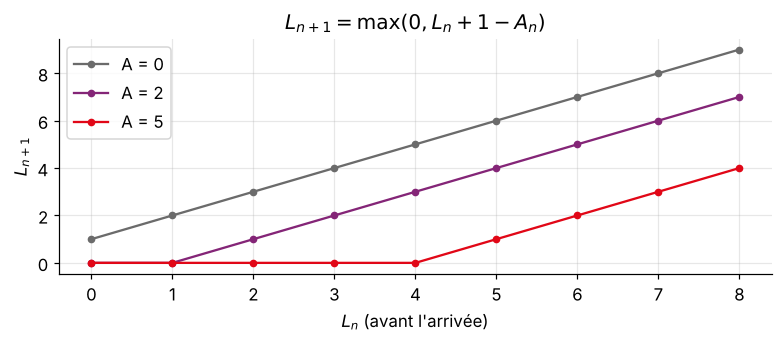

In [27]:
l = np.arange(0, 9)
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
for a, c in [(0, GRIS), (2, VIOLET), (5, ROUGE)]:
    ax.plot(l, np.maximum(0, l + 1 - a), "o-", color=c, ms=4, label=f"A = {a}")
ax.set_xlabel(r"$L_n$ (avant l'arrivée)"); ax.set_ylabel(r"$L_{n+1}$")
ax.set_title(r"$L_{n+1} = \max(0, L_n + 1 - A_n)$"); ax.legend(); plt.show()

### 🧮 Calcul
| Étape | Raisonnement | Pourquoi on a le droit |
|---|---|---|
| 1. Services possibles | tant que la file n'est pas vide, la fin du service en cours arrive au taux $\mu$, quel que soit le temps déjà passé | absence de mémoire de $\mathcal E(\mu)$ (A.2) |
| 2. Un seul processus | on tire un processus de Poisson $N(t)$ d'intensité $\mu$ ; chaque point fait partir un client s'il y en a, sinon il est perdu | même taux de départ que la vraie file : même loi pour $L(t)$ |
| 3. Après l'arrivée $n$ | il y a $L_n + 1$ clients | $L_n$ avant, plus le nouveau |
| 4. Pendant $[T_n, T_{n+1}[$ | aucune arrivée ; $A_n$ points de $N$ | définition de $T_{n+1}$ et de $A_n$ |
| 5. Départs | $\min(A_n, L_n + 1)$ | on ne fait pas partir plus de clients qu'il n'y en a |
| 6. Conclure | $L_{n+1} = L_n + 1 - \min(A_n, L_n + 1) = \max(0, L_n + 1 - A_n)$ | $a - \min(b, a) = \max(a - b, 0)$ |

$$\boxed{L_1 = 0,\qquad L_{n+1} = (L_n + 1 - A_n)^+}$$

**Loi de $A_n$** : sachant l'écart $s = T_{n+1} - T_n$, $A_n \sim \mathcal P(\mu s)$ (B.3) ; en
intégrant contre la densité $\lambda e^{-\lambda s}$ de l'écart :
$P(A_n = k) = \frac{\lambda}{\lambda + \mu}\big(\frac{\mu}{\lambda+\mu}\big)^k$, loi géométrique de
moyenne $\mu/\lambda$.

### 🐍 Code
Le notebook de rendu fait évoluer $L(t)$ événement par événement sur une petite fenêtre
($\lambda = 1$, $\mu = 1{,}2$), puis compare avec la récurrence calculée par `longueur_recurrence`.
Voici cette fonction, puis la même cellule que le rendu (tirage n° 7 de `rng`).

def longueur_recurrence(A):
    """L_1 = 0 et L_{n+1} = max(0, L_n + 1 - A_n), calculé pas à pas."""
    L = np.zeros(len(A) + 1, dtype=np.int64)
    for n, a in enumerate(A):
        L[n + 1] = max(0, L[n] + 1 - a)
    return L

n    : [ 1  2  3  4  5  6  7  8  9 10 11 12]
L_n  : [0 0 0 0 0 1 0 1 2 2 1 0]
A_n  : [1 1 6 4 0 2 0 0 1 2 2]
récurrence identique au parcours des événements : True


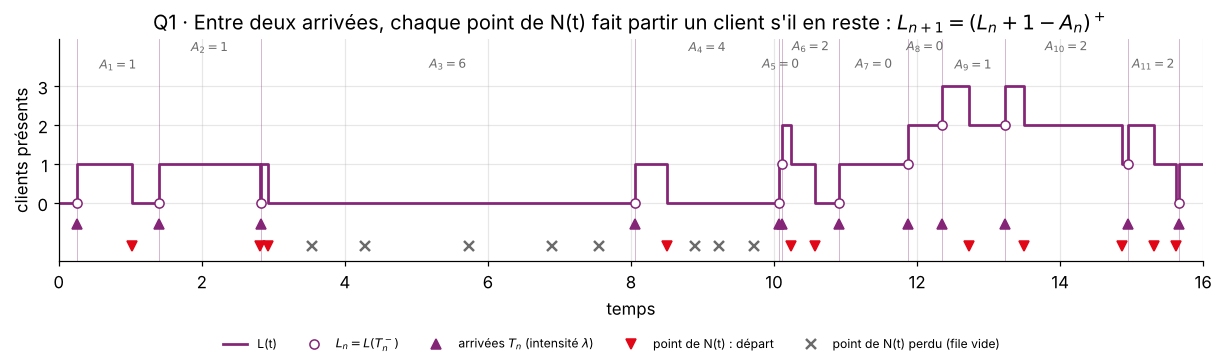

In [28]:
print(inspect.getsource(longueur_recurrence))

# Q1 : une petite trajectoire en temps continu, construite avec les services potentiels N(t)
lam1, mu1, fin = 1.0, 1.2, 16.0                  # même charge ρ = 5/6 que la Q5, échelle lisible
def instants(intensite, fin):
    t, out = 0.0, []
    while True:
        t += -np.log(1.0 - rng.random()) / intensite
        if t > fin:
            return np.array(out)
        out.append(t)
arr, serv = instants(lam1, fin), instants(mu1, fin)

# Parcours des événements dans l'ordre du temps : arrivée -> +1 ; service potentiel -> -1 si L > 0
ev = sorted([(t, "a") for t in arr] + [(t, "s") for t in serv])
l, temps, niveaux, Ln, depart, perdu = 0, [0.0], [0], [], [], []
for t, e in ev:
    if e == "a":
        Ln.append(l); l += 1                     # L_n = L(T_n^-) : relevé juste avant l'arrivée
    elif l > 0:
        l -= 1; depart.append(t)
    else:
        perdu.append(t)                          # file vide : service potentiel perdu
    temps.append(t); niveaux.append(l)
A = np.diff(np.searchsorted(serv, arr))          # A_n = N(T_{n+1}) - N(T_n)
L_rec = longueur_recurrence(A)                   # L_1 = 0, L_{n+1} = max(0, L_n + 1 - A_n)
print("n    :", np.arange(1, len(arr) + 1))
print("L_n  :", np.array(Ln))
print("A_n  :", A)
print("récurrence identique au parcours des événements :", np.array_equal(L_rec, Ln))
resultats.update(Q1_n=len(arr), Q1_L=list(map(int, Ln)), Q1_A=list(map(int, A)),
                 Q1_perdus=len(perdu))

fig, ax = plt.subplots(figsize=(11, 3.2), layout="constrained")
ax.step(temps + [fin], niveaux + [niveaux[-1]], where="post", color=VIOLET, lw=1.8, label="L(t)")
ax.plot(arr, Ln, "o", color=VIOLET, mfc="white", ms=6, zorder=3, label=r"$L_n = L(T_n^-)$")
for t in arr:
    ax.axvline(t, color=VIOLET, lw=0.6, alpha=0.35)
ax.plot(arr, np.full(len(arr), -0.55), "^", color=VIOLET, ms=7, label=r"arrivées $T_n$ (intensité $\lambda$)")
ax.plot(depart, np.full(len(depart), -1.1), "v", color=ROUGE, ms=7, label="point de N(t) : départ")
ax.plot(perdu, np.full(len(perdu), -1.1), "x", color=GRIS, ms=7, mew=1.6, label="point de N(t) perdu (file vide)")
for n in range(len(A)):                          # A_n au milieu de [T_n, T_{n+1}[, sur deux rangées
    ax.text((arr[n] + arr[n + 1]) / 2, max(niveaux) + 0.45 + 0.45 * (n % 2), f"$A_{{{n+1}}}={A[n]}$",
            ha="center", fontsize=8, color=GRIS)
ax.set_ylim(-1.5, max(niveaux) + 1.2); ax.set_xlim(0, fin)
ax.set_xlabel("temps"); ax.set_ylabel("clients présents")
ax.set_yticks(range(0, max(niveaux) + 1))
fig.legend(fontsize=8, loc="outside lower center", ncol=5, frameon=False)
ax.set_title(r"Q1 · Entre deux arrivées, chaque point de N(t) fait partir un client s'il en reste : $L_{n+1}=(L_n+1-A_n)^+$")
plt.show()

### 📊 Lecture
Sur 12 arrivées, la récurrence redonne exactement $L_n = 0, 0, 0, 0, 0, 1, 0, 1, 2, 2, 1, 0$.
Entre les arrivées 3 et 4 : un seul client présent, $A_3 = 6$ services possibles, un départ et 5
points « perdus » (croix grises). C'est le $\max(0, \cdot)$ qui les absorbe.

### ⚠️ Pièges
- Dire que $N(t)$ compte les **départs** : il compte les départs **possibles**.
- Oublier le $+1$ (le client qui vient d'arriver compte).
- Oublier que $L$ inclut le client en service.
- Ne pas savoir **pourquoi** on peut tirer les services à l'avance : c'est l'absence de mémoire.

### ✋ À toi
À la main : $L_1 = 0$ et $A = (0, 3, 0, 0, 4)$. Calcule $L_2, \dots, L_6$, puis vérifie avec
`longueur_recurrence`.

In [29]:
# print(longueur_recurrence([0, 3, 0, 0, 4]))

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

$L_2 = \max(0, 0 + 1 - 0) = 1$ ; $L_3 = \max(0, 1 + 1 - 3) = 0$ ; $L_4 = 1$ ; $L_5 = 2$ ;
$L_6 = \max(0, 2 + 1 - 4) = 0$.
```python
print(longueur_recurrence([0, 3, 0, 0, 4]))   # [0 1 0 1 2 0]
```

</details>

### 🗣️ La réponse en 30 secondes
<details>
<summary><b>Ce que je dis au jury</b></summary>

« Grâce à l'absence de mémoire, les fins de service arrivent au taux $\mu$ tant que la file n'est pas
vide : je les représente par un processus de Poisson $N(t)$ de services possibles. Juste après la
$n$-ième arrivée il y a $L_n + 1$ clients ; les $A_n$ points de $N$ avant l'arrivée suivante en font
partir $\min(A_n, L_n + 1)$, donc $L_{n+1} = \max(0, L_n + 1 - A_n)$. »

</details>

### 🎤 Jury
Questions 15, 16 et 17 de [questions_oral.md](questions_oral.md). Piège : « Que se passe-t-il pour
les points de $N(t)$ quand la file est vide ? » (ils sont perdus, d'où le max).

## Q2 · Algorithme de simulation

### 🎯 Objectif
> *Énoncé.* En déduire un algorithme de simulation de l'évolution de la longueur de la file
> d'attente. Implémenter cet algorithme.

**Ce qu'on demande vraiment** : traduire la récurrence en boucle, en tirant à chaque pas l'écart
entre deux arrivées et le nombre de services possibles, avec les outils A, B, S.

### 💡 Intuition
**À chaque arrivée : tirer l'écart, tirer $A_n$, mettre à jour $L$.** Ci-dessous, 25 pas de
l'algorithme ($\lambda = 100$, $\mu = 120$) : les barres grises sont les $A_n$, la courbe violette les
$L_n$.

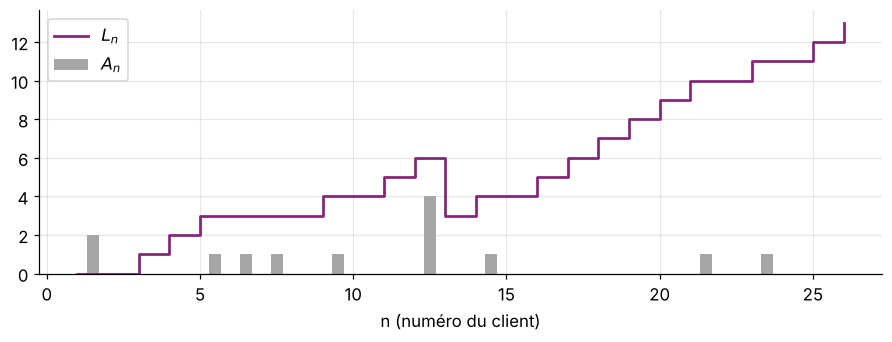

In [30]:
l, Ls, As = 0, [0], []
for n in range(25):
    s = exponentielle_inversion(100.0, 1, rng_fig)[0]      # écart entre deux arrivées
    A = nombre_points_poisson(120.0, s, rng_fig)            # services possibles pendant s
    l = max(0, l + 1 - A); Ls.append(l); As.append(A)
fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
ax.bar(np.arange(1, 26) + 0.5, As, width=0.4, color=GRIS, alpha=0.6, label=r"$A_n$")
ax.step(np.arange(1, 27), Ls, where="post", color=VIOLET, lw=1.8, label=r"$L_n$")
ax.set_xlabel("n (numéro du client)"); ax.legend(); plt.show()

### 🧮 Calcul
| Étape | Instruction | D'où ça vient |
|---|---|---|
| 1. Départ | $t \leftarrow \mathcal E(\lambda)$ (instant $T_1$), $l \leftarrow 0$ | file vide à $t = 0$ |
| 2. Écart | $s \leftarrow -\ln(1 - U)/\lambda$ | arrivées poissoniennes ; S.1 |
| 3. Services | $A \leftarrow$ nombre de sommes de $\mathcal E(\mu)$ $\le s$ | $A_n \sim \mathcal P(\mu s)$ ; B.3 et S.2 |
| 4. Mise à jour | $l \leftarrow \max(0, l + 1 - A)$ | Q1 |
| 5. Temps | $t \leftarrow t + s$ ; recommencer tant que $t \le$ durée | |

**Variante vectorisée** : tirer d'un coup tous les instants d'arrivée et tous les points de $N(t)$,
compter avec `np.searchsorted`, puis la formule de **Lindley** $L_n = S_n - \min_{k \le n}S_k$ avec
$S_n = \sum_{k<n}(1 - A_k)$ (démontrée en Q3).

### 🐍 Code
Les trois fonctions, puis la même cellule que le rendu : on simule 5 minutes avec $\lambda = 100$,
$\mu = 120$ par trois méthodes et on compare (tirages n° 8 à 10 de `rng`).

In [31]:
print(inspect.getsource(file_mm1))
print(inspect.getsource(longueur_lindley))
print(inspect.getsource(file_mm1_evenements))

# Q2 : l'algorithme (src/stats_td/files_attente.py, fonction file_mm1), validé contre deux autres
lam, mu, duree = 100.0, 120.0, 300.0
rho = lam / mu
th = indicateurs_theoriques(rho)
_, L_rec = file_mm1(lam, mu, duree, rng)                  # récurrence pas à pas (l'algorithme)
_, L_vec, _ = file_mm1_vectorisee(lam, mu, duree, rng)    # même modèle, formule de Lindley
_, L_dir = file_mm1_evenements(lam, mu, len(L_rec), rng)  # simulation directe FIFO (services propres)
print(f"{'méthode':28s} {'n':>6s} {'E[L]':>7s} {'P(L=0)':>8s} {'P(L>5)':>8s}   écarts à la théorie (e.-t., méthode des lots)")
print(f"{'théorie (ρ = 5/6)':28s} {'':>6s} {th['moyenne']:7.3f} {th['p_serveur_libre']:8.4f} {th['p_plus_de_5']:8.4f}")
valid = {}
for nom, L in [("récurrence (algorithme)", L_rec), ("Lindley vectorisée", L_vec), ("directe FIFO", L_dir)]:
    z = [(moyenne_par_lots(v, 30)[0] - th[c]) / moyenne_par_lots(v, 30)[1]
         for v, c in [(L, "moyenne"), (L == 0, "p_serveur_libre"), (L > 5, "p_plus_de_5")]]
    valid[nom] = dict(n=len(L), moyenne=L.mean(), p0=np.mean(L == 0), p_plus_5=np.mean(L > 5), z=z)
    print(f"{nom:28s} {len(L):6d} {L.mean():7.3f} {np.mean(L == 0):8.4f} {np.mean(L > 5):8.4f}   "
          + "  ".join(f"{v:+.2f}" for v in z))
resultats["Q2_validation"] = valid

def file_mm1(lam, mu, duree, rng):
    """File M/M/1 simulée par la récurrence L_{n+1} = max(0, L_n + 1 - A_n).

    - écart entre deux arrivées s = T_{n+1} - T_n ~ E(lam) (inversion) ;
    - A_n = nombre de services potentiels pendant s ~ P(mu * s) (comptage
      d'exponentielles E(mu)) ;
    - la file est vide à t = 0 : L_1 = 0.
    Renvoie (T, L) : instants d'arrivée dans [0, duree] et longueur juste avant
    chaque arrivée.
    """
    if lam <= 0 or mu <= 0:
        raise ValueError("lambda et mu doivent être strictement positifs")
    T, L = [], []
    t, l = _expo(lam, rng), 0  # T_1 et L_1 = 0
    while t <= duree:
        T.append(t)
        L.append(l)
        s = _expo(lam, rng)                      # T_{n+1} - T_n
        A = nombre_points_poisson(mu, s, rng)    # services potentiels sur [T_n, T_{n+1}[
        l = max(0, l + 1 - A)                    # récurrence (Q1)
        t += s
    return np.array(T), np.array(L, dtype=np.int64)

def longueur_lindley(A):
    """Même 

### 📊 Lecture
Les trois simulations donnent la même chose, à l'erreur de simulation près : file moyenne $4{,}955$ ;
$5{,}054$ ; $5{,}201$ (théorie 5), $P(L = 0)$ entre $0{,}155$ et $0{,}165$ (théorie $0{,}167$), $P(L > 5)$
entre $0{,}338$ et $0{,}349$ (théorie $0{,}335$). Le plus grand écart vaut $-2{,}00$ erreurs-types (sur
$P(L = 0)$ avec la récurrence), à la limite des 95 % : sur 9 comparaisons, en voir un est normal. La
troisième méthode ne connaît pas la récurrence (chaque client a son propre service) : l'accord valide
la Q1.

### ⚠️ Pièges
- Oublier $L_1 = 0$ (file vide au départ).
- Tirer $A_n$ avec une loi de Poisson de paramètre $\mu$ au lieu de $\mu s$.
- Comparer des simulations sans erreur-type : « 4,96 contre 5,20 » ne veut rien dire sans elle.

### ✋ À toi
La probabilité que $A_n = 0$ (aucun service possible entre deux arrivées) vaut
$\frac{\lambda}{\lambda+\mu}$. Calcule-la pour $\lambda = 100$, $\mu = 120$ et vérifie avec
`file_mm1_vectorisee` et `rng_exo`.

In [32]:
# _, _, A = file_mm1_vectorisee(100.0, 120.0, 300.0, rng_exo)
# print(np.mean(A == 0), 100 / 220)

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

$\frac{100}{220} \approx 0{,}455$ : presque une fois sur deux, le client suivant arrive avant la fin
du service en cours.
```python
_, _, A = file_mm1_vectorisee(100.0, 120.0, 300.0, rng_exo)
print(np.mean(A == 0), 100 / 220, A.mean(), 120 / 100)   # et E[A] = μ/λ = 1,2
```

</details>

### 🗣️ La réponse en 30 secondes
<details>
<summary><b>Ce que je dis au jury</b></summary>

« Ma boucle tire à chaque arrivée l'écart avec la suivante, de loi $\mathcal E(\lambda)$ par
inversion, puis le nombre de services possibles $A_n$, de loi de Poisson de paramètre $\mu s$, en
comptant des exponentielles, et applique la récurrence. Je l'ai validée contre une version
vectorisée et une simulation directe où chaque client a son propre service : mêmes indicateurs, à
moins de 2 erreurs-types. »

</details>

### 🎤 Jury
Questions 18 et 19 de [questions_oral.md](questions_oral.md). Piège : « Comment savez-vous que
votre code est juste ? » (validation croisée + théorie + tests).

## Q3 · Si $\rho > 1$, la file croît indéfiniment

### 🎯 Objectif
> *Énoncé.* $\rho > 1$ : choisir deux valeurs de $\lambda$ et $\mu$ telles que $\rho > 1$ et montrer
> par simulation que la file croît alors indéfiniment.

**Ce qu'on demande vraiment** : quand il arrive plus de clients que le serveur ne peut en traiter
($\lambda > \mu$), la file ne fait que grossir. On choisit $\lambda = 120$, $\mu = 100$
($\rho = 1{,}2$), et une surcharge légère $\lambda = 105$ ($\rho = 1{,}05$).

### 💡 Intuition
**Chaque arrivée ajoute 1, chaque intervalle retire en moyenne $1/\rho < 1$ : la file monte en
moyenne de $1 - 1/\rho$ par client.** La somme $S_n = \sum(1 - A_k)$ est une marche aléatoire qui
monte ; $L_n$ la suit (et reste au-dessus).

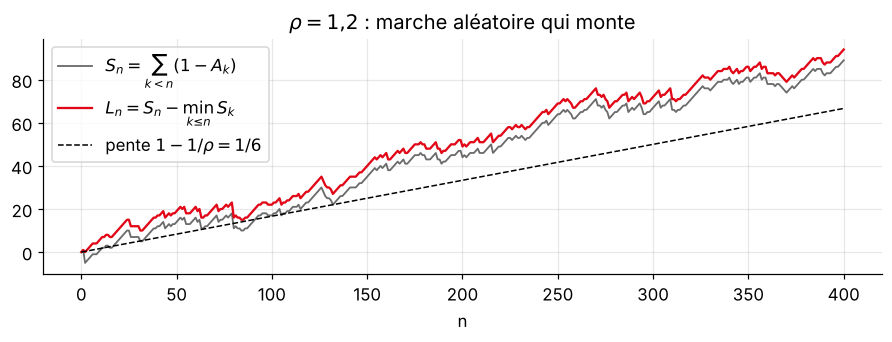

In [33]:
lam_f, mu_f, n_f = 120.0, 100.0, 400
p_f = lam_f / (lam_f + mu_f)
A_f = rng_fig.geometric(p_f, n_f) - 1           # P(A = k) = p q^k, k >= 0 (géométrique, Q1)
S_f = np.concatenate([[0], np.cumsum(1 - A_f)])
L_f = longueur_lindley(A_f)
fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
ax.plot(S_f, color=GRIS, lw=1.2, label=r"$S_n = \sum_{k<n}(1 - A_k)$")
ax.plot(L_f, color=ROUGE, lw=1.5, label=r"$L_n = S_n - \min_{k \leq n} S_k$")
ax.plot([0, n_f], [0, n_f * (1 - mu_f / lam_f)], "k--", lw=1, label=r"pente $1 - 1/\rho = 1/6$")
ax.set_xlabel("n"); ax.legend(); ax.set_title(r"$\rho = 1{,}2$ : marche aléatoire qui monte"); plt.show()

### 🧮 Calcul
| Étape | Calcul | Pourquoi on a le droit |
|---|---|---|
| 1. Notation | $\Delta_k = 1 - A_k$, $S_n = \sum_{k<n}\Delta_k$, $S_1 = 0$ | |
| 2. Lindley | $L_n = S_n - \min_{1 \le k \le n}S_k$ | récurrence : $\max(0, S_n - m_n + \Delta_n) = S_{n+1} - \min(S_{n+1}, m_n)$ |
| 3. Minoration | $L_n \ge S_n$ | $\min_k S_k \le S_1 = 0$ |
| 4. Moyenne | $E[\Delta_k] = 1 - E[A_k] = 1 - \mu/\lambda = 1 - 1/\rho$ | loi de $A_n$ (Q1) |
| 5. LGN | $S_n/n \to 1 - 1/\rho > 0$ p.s. | $\Delta_k$ indépendants de même loi ; $\rho > 1$ |
| 6. Conclure | $L_n \to +\infty$ et $L_n/n \to 1 - 1/\rho$ | le minimum finit par se figer |
| 7. En temps | $L(t) \approx (1 - \mu/\lambda)\lambda t = (\lambda - \mu)t$ | environ $\lambda t$ arrivées en un temps $t$ |

$$\boxed{\rho > 1 :\ \frac{L_n}{n} \to 1 - \frac{1}{\rho},\quad L(t) \approx (\lambda - \mu)\,t}$$

### 🐍 Code
La formule de Lindley sert dans la version vectorisée (`longueur_lindley`, affichée en Q2). Ici on
utilise `file_mm1` (la boucle) pendant 60 s, comme dans le rendu (tirages n° 11 et 12 de `rng`).

ρ = 1.20 : L à 60 s =  1099   pente 18.40 clients/s (théorie λ - μ = 20)   L_n/n = 0.1540 (théorie 1 - 1/ρ = 0.1667)


ρ = 1.05 : L à 60 s =   316   pente  6.26 clients/s (théorie λ - μ = 5)   L_n/n = 0.0497 (théorie 1 - 1/ρ = 0.0476)


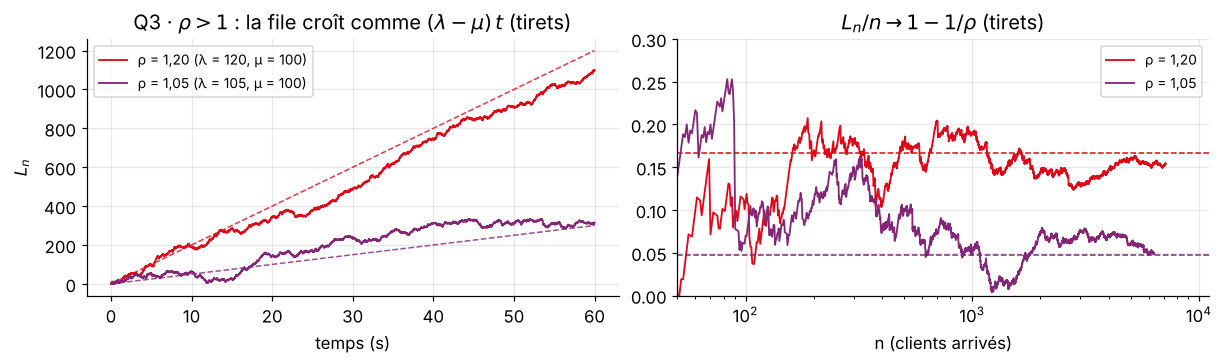

In [34]:
# Q3 : ρ > 1, la file croît sans fin
duree = 60.0
sur = {}
for lam, mu in [(120.0, 100.0), (105.0, 100.0)]:
    Tq, Lq = file_mm1(lam, mu, duree, rng)
    pente_t = np.polyfit(Tq, Lq, 1)[0]                 # clients gagnés par seconde
    sur[lam / mu] = (Tq, Lq)
    print(f"ρ = {lam/mu:.2f} : L à 60 s = {Lq[-1]:5d}   pente {pente_t:5.2f} clients/s (théorie λ - μ = {lam-mu:.0f})"
          f"   L_n/n = {Lq[-1]/len(Lq):.4f} (théorie 1 - 1/ρ = {1 - mu/lam:.4f})")
    resultats[f"Q3_rho_{lam/mu:.2f}"] = dict(L_fin=int(Lq[-1]), pente=pente_t, Ln_sur_n=Lq[-1] / len(Lq))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), layout="constrained")
for (r, (Tq, Lq)), c in zip(sur.items(), (ROUGE, VIOLET)):
    lam = r * 100
    axs[0].plot(Tq, Lq, color=c, lw=1.2, label=virgule(f"ρ = {r:.2f} (λ = {lam:.0f}, μ = 100)"))
    axs[0].plot([0, duree], [0, (lam - 100) * duree], "--", color=c, lw=1, alpha=0.8)
    n = np.arange(1, len(Lq) + 1)
    axs[1].plot(n, Lq / n, color=c, lw=1.2, label=virgule(f"ρ = {r:.2f}"))
    axs[1].axhline(1 - 1 / r, color=c, ls="--", lw=1)
axs[0].set_title(r"Q3 · $\rho > 1$ : la file croît comme $(\lambda-\mu)\,t$ (tirets)")
axs[0].set_xlabel("temps (s)"); axs[0].set_ylabel(r"$L_n$"); axs[0].legend(fontsize=9)
axs[1].set_xscale("log"); axs[1].set_ylim(0, 0.3); axs[1].set_xlim(50, None)
axs[1].set_title(r"$L_n / n \to 1 - 1/\rho$ (tirets)"); axs[1].set_xlabel("n (clients arrivés)")
axs[1].legend(fontsize=9)
plt.show()

### 📊 Lecture
Avec $\rho = 1{,}2$ : **1099 clients** après 60 s, environ $18{,}4$ de plus par seconde (théorie
$\lambda - \mu = 20$), et $L_n/n = 0{,}154$ pour $1 - 1/\rho = 0{,}167$. L'écart, $0{,}013$, vaut environ
$0{,}9$ écart-type de $S_n/n$ ($\sqrt{\operatorname{Var}A/n} \approx \sqrt{1{,}53/7200} \approx 0{,}015$) :
normal. Avec 5 % de surcharge : 316 clients, $L_n/n = 0{,}050$ pour $0{,}048$. La pente « mesurée »
par régression ($6{,}3$ au lieu de 5) est bruitée : sur 60 s, une marche aléatoire s'écarte beaucoup de
sa tendance. C'est $L_n/n$ qui converge, lentement.

### ⚠️ Pièges
- Dire « la file croît » sans quantifier : il faut la vitesse $(\lambda - \mu)$ par seconde.
- Croire qu'une petite surcharge est sans danger : $\rho = 1{,}05$ suffit à faire diverger la file.
- $\rho = 1$ : pas de dérive, mais pas de stabilité non plus (récurrence nulle, croissance en $\sqrt n$).

### ✋ À toi
Pour $\lambda = 150$, $\mu = 100$, prédis la longueur de la file après 60 s, puis vérifie avec
`file_mm1_vectorisee` et `rng_exo`.

In [35]:
# T150, L150, _ = file_mm1_vectorisee(150.0, 100.0, 60.0, rng_exo)
# print(L150[-1], (150 - 100) * 60)

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

$(\lambda - \mu)\,t = 50 \times 60 = 3000$ clients environ.
```python
T150, L150, _ = file_mm1_vectorisee(150.0, 100.0, 60.0, rng_exo)
print(L150[-1], L150[-1] / len(L150), 1 - 100 / 150)   # ≈ 3000 ; L_n/n ≈ 1/3
```

</details>

### 🗣️ La réponse en 30 secondes
<details>
<summary><b>Ce que je dis au jury</b></summary>

« Si $\rho > 1$, chaque intervalle ne retire en moyenne que $\mu/\lambda < 1$ client alors qu'une
arrivée en ajoute un. Avec la formule de Lindley, $L_n$ est au-dessus de la marche aléatoire
$S_n = \sum(1 - A_k)$, qui croît comme $n(1 - 1/\rho)$ par la loi des grands nombres. En simulation,
avec $\lambda = 120$ et $\mu = 100$, la file atteint 1099 clients en une minute, environ 20 de plus par
seconde. »

</details>

### 🎤 Jury
Questions 20 et 21 de [questions_oral.md](questions_oral.md). Piège : « Et si $\rho = 1$ ? »
(récurrente nulle, pas de régime stationnaire).

## Q4 · Si $\rho < 1$, la file se stationnarise

### 🎯 Objectif
> *Énoncé.* $\rho < 1$ : choisir deux valeurs de $\lambda$ et $\mu$ telles que $\rho < 1$ et montrer par
> simulation que le comportement de la file se stationnarise.

**Ce qu'on demande vraiment** : montrer que la file ne dérive pas : elle fluctue autour d'un niveau
fixe et sa **loi** finit par ne plus changer (régime stationnaire). On prend $\mu = 100$ avec
$\lambda = 60$ ($\rho = 0{,}6$) et $\lambda = 90$ ($\rho = 0{,}9$).

### 💡 Intuition
**La marche $S_n$ descend ; $L_n = S_n - \min S$ mesure la hauteur au-dessus du plus bas atteint :
elle « rebondit » sur 0 sans cesse.** C'est une marche aléatoire réfléchie en 0.

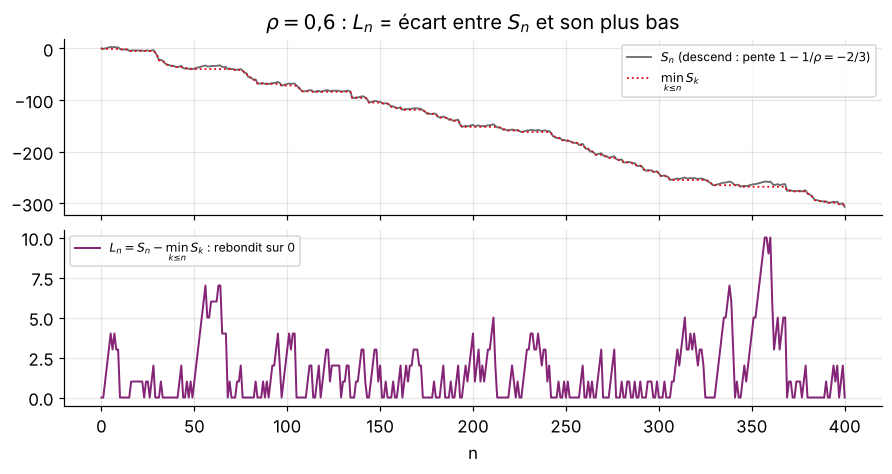

In [36]:
lam_f, mu_f, n_f = 60.0, 100.0, 400
p_f = lam_f / (lam_f + mu_f)
A_f = rng_fig.geometric(p_f, n_f) - 1
S_f = np.concatenate([[0], np.cumsum(1 - A_f)])
L_f = longueur_lindley(A_f)
fig, axs = plt.subplots(2, 1, figsize=(8, 4.2), sharex=True, layout="constrained")
axs[0].plot(S_f, color=GRIS, lw=1.2, label=r"$S_n$ (descend : pente $1 - 1/\rho = -2/3$)")
axs[0].plot(np.minimum.accumulate(S_f), color=ROUGE, ls=":", lw=1.2, label=r"$\min_{k \leq n} S_k$")
axs[0].legend(fontsize=8); axs[0].set_title(r"$\rho = 0{,}6$ : $L_n$ = écart entre $S_n$ et son plus bas")
axs[1].plot(L_f, color=VIOLET, lw=1.3, label=r"$L_n = S_n - \min_{k \leq n} S_k$ : rebondit sur 0")
axs[1].set_xlabel("n"); axs[1].legend(fontsize=8); plt.show()

### 🧮 Calcul
| Étape | Raisonnement | Pourquoi on a le droit |
|---|---|---|
| 1. Dérive | $E[1 - A_k] = 1 - 1/\rho < 0$ | $\rho < 1$ |
| 2. Retours en 0 | $S_n \to -\infty$, donc le minimum est sans cesse battu et $L_n = 0$ infiniment souvent | Lindley |
| 3. Chaîne de Markov | $L_{n+1}$ ne dépend que de $L_n$ et de $A_n$, indépendant du passé | les $A_n$ sont indépendants |
| 4. Bonnes propriétés | irréductible, apériodique ($P(0 \to 0) > 0$), récurrente positive | retours en 0 de durée moyenne finie |
| 5. Conclusion | $L_n$ converge **en loi** vers une loi stationnaire unique $\pi$ | théorème de convergence des chaînes de Markov |
| 6. Moyennes | $\frac1n\sum_{k \le n}L_k \to E_\pi[L]$ | théorème ergodique |

« Se stationnariser » veut dire : la **loi** de $L_n$ se stabilise ; la trajectoire, elle, continue
de bouger. La loi $\pi$ est calculée en Q5 : $(1-\rho)\rho^k$, de moyenne $\rho/(1-\rho)$.

### 🐍 Code
Même cellule que le rendu (tirages n° 13 et 14 de `rng`), avec la méthode des lots pour l'erreur-type
(expliquée en Q5) :

def moyenne_par_lots(x, n_lots=30):
    """Moyenne et erreur-type par la méthode des lots (batch means).

    Les valeurs successives sont corrélées : on coupe la série en n_lots blocs
    contigus, on moyenne chaque bloc, et on traite ces moyennes comme à peu près
    indépendantes : erreur-type = écart-type des moyennes / sqrt(n_lots) (ddof=1).
    """
    x = np.asarray(x, dtype=float)
    taille = len(x) // n_lots
    if taille < 1:
        raise ValueError("trop de lots pour la longueur de la série")
    lots = x[: taille * n_lots].reshape(n_lots, taille).mean(axis=1)
    return lots.mean(), lots.std(ddof=1) / np.sqrt(n_lots)

ρ = 0.6 : n = 7150   moyenne 1.440 ± 0.078 (théorie ρ/(1-ρ) = 1.500, écart -0.78 e.-t.)   max 14   part du temps file vide 0.408
ρ = 0.9 : n = 10723   moyenne 10.138 ± 1.791 (théorie ρ/(1-ρ) = 9.000, écart +0.64 e.-t.)   max 64   part du temps file vide 0.115


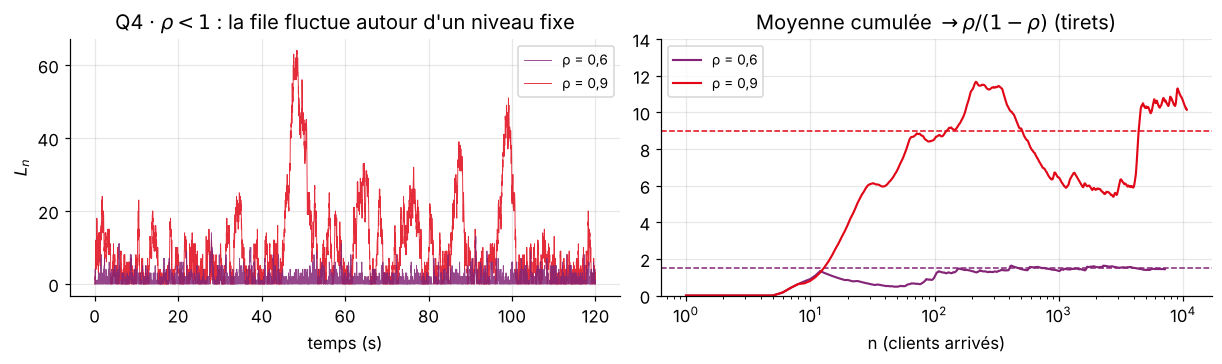

In [37]:
print(inspect.getsource(moyenne_par_lots))

# Q4 : ρ < 1, la file se stationnarise
duree = 120.0
stab = {}
for lam, mu in [(60.0, 100.0), (90.0, 100.0)]:
    Tq, Lq = file_mm1(lam, mu, duree, rng)
    r = lam / mu
    m, se = moyenne_par_lots(Lq, 20)
    stab[r] = (Tq, Lq)
    print(f"ρ = {r:.1f} : n = {len(Lq)}   moyenne {m:.3f} ± {se:.3f} (théorie ρ/(1-ρ) = {r/(1-r):.3f}, "
          f"écart {(m - r/(1-r))/se:+.2f} e.-t.)   max {Lq.max()}   part du temps file vide {np.mean(Lq == 0):.3f}")
    resultats[f"Q4_rho_{r:.1f}"] = dict(n=len(Lq), moyenne=m, se=se, max=int(Lq.max()), p0=np.mean(Lq == 0))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), layout="constrained")
for (r, (Tq, Lq)), c in zip(stab.items(), (VIOLET, ROUGE)):
    axs[0].plot(Tq, Lq, color=c, lw=0.6, alpha=0.85, label=virgule(f"ρ = {r:.1f}"), zorder=3 if r < 0.7 else 2)
    n = np.arange(1, len(Lq) + 1)
    axs[1].plot(n, np.cumsum(Lq) / n, color=c, lw=1.4, label=virgule(f"ρ = {r:.1f}"))
    axs[1].axhline(r / (1 - r), color=c, ls="--", lw=1)
axs[0].set_title(r"Q4 · $\rho < 1$ : la file fluctue autour d'un niveau fixe")
axs[0].set_xlabel("temps (s)"); axs[0].set_ylabel(r"$L_n$"); axs[0].legend(fontsize=9)
axs[1].set_xscale("log"); axs[1].set_ylim(0, 14)
axs[1].set_title(r"Moyenne cumulée $\to \rho/(1-\rho)$ (tirets)"); axs[1].set_xlabel("n (clients arrivés)")
axs[1].legend(fontsize=9)
plt.show()

### 📊 Lecture
Les deux files reviennent sans cesse à 0 et restent bornées (maximum 14 pour $\rho = 0{,}6$, 64 pour
$\rho = 0{,}9$). La moyenne cumulée se fixe : $1{,}44 \pm 0{,}08$ pour $1{,}5$ ($-0{,}8$ e.-t.) et
$10{,}1 \pm 1{,}8$ pour 9 ($+0{,}6$ e.-t.). Pour $\rho = 0{,}9$ la courbe rouge est encore très bruitée
après $10^4$ clients : plus $\rho$ est proche de 1, plus les excursions sont longues et plus il faut
simuler longtemps.

### ⚠️ Pièges
- Dire que $L_n$ « devient constant » : c'est la **loi** qui converge.
- Conclure sur un seul petit morceau de trajectoire : il faut la moyenne cumulée et une erreur-type.
- Oublier que la convergence est lente quand $\rho$ est proche de 1.

### ✋ À toi
Pour $\rho = 0{,}5$ ($\lambda = 50$, $\mu = 100$), prédis $E[L]$ et la proportion de clients qui
trouvent le serveur libre, puis vérifie avec `file_mm1_vectorisee` (5 min, `rng_exo`).

In [38]:
# _, L05, _ = file_mm1_vectorisee(50.0, 100.0, 300.0, rng_exo)
# print(moyenne_par_lots(L05), moyenne_par_lots(L05 == 0))

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

$E[L] = 0{,}5/0{,}5 = 1$ et $P(L = 0) = 1 - \rho = 0{,}5$.
```python
_, L05, _ = file_mm1_vectorisee(50.0, 100.0, 300.0, rng_exo)
print(moyenne_par_lots(L05), moyenne_par_lots(L05 == 0))   # ≈ (1, e.-t.) et (0,5, e.-t.)
```

</details>

### 🗣️ La réponse en 30 secondes
<details>
<summary><b>Ce que je dis au jury</b></summary>

« Si $\rho < 1$, la marche $\sum(1 - A_k)$ descend, donc la file revient sans cesse à 0. C'est une
chaîne de Markov récurrente positive : sa loi converge vers une loi stationnaire, et la moyenne
cumulée converge vers la moyenne de cette loi. En simulation, la moyenne se fixe à $1{,}44 \pm 0{,}08$
pour $\rho = 0{,}6$ (théorie $1{,}5$) et $10{,}1 \pm 1{,}8$ pour $\rho = 0{,}9$ (théorie 9). »

</details>

### 🎤 Jury
Question 22 de [questions_oral.md](questions_oral.md). Piège : « Stationnaire, ça veut dire que la
file ne bouge plus ? » (non, c'est sa loi qui ne bouge plus).

## Q5 · $\lambda = 100$, $\mu = 120$ : la loi géométrique et les indicateurs

### 🎯 Objectif
> *Énoncé.* $\lambda = 100$ arrivées par seconde, $\mu = 120$ départs par seconde. Simuler 5 minutes.
> Vérifier que $P(L_n = k) = (1-\rho)\rho^k$ où ~~$\rho = \mu/\lambda$~~. En déduire la moyenne et la
> variance de la longueur, la probabilité de trouver le serveur libre, et celle de trouver plus de 5
> clients, et vérifier par simulation.

**Coquille** : il faut $\rho = \lambda/\mu = 5/6$ ; avec $\mu/\lambda = 1{,}2$, $(1-\rho)\rho^k$ serait
négatif. « Plus de 5 » est lu $L > 5$.

### 💡 Intuition
**En échelle logarithmique, une loi géométrique est une droite de pente $\ln\rho$ : plus $\rho$ est
proche de 1, plus la droite est plate, donc plus les longues files sont probables.**

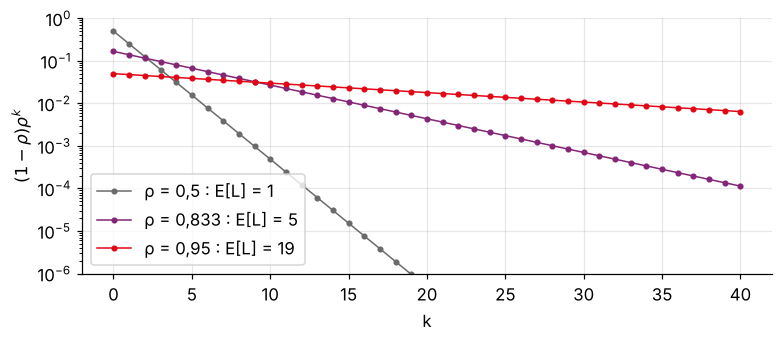

In [39]:
k = np.arange(0, 41)
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
for r, c in [(0.5, GRIS), (5 / 6, VIOLET), (0.95, ROUGE)]:
    ax.plot(k, loi_stationnaire(r, k), "o-", color=c, ms=3, lw=1, label=virgule(f"ρ = {r:.3g} : E[L] = {r/(1-r):.3g}"))
ax.set_yscale("log"); ax.set_ylim(1e-6, 1); ax.set_xlabel("k"); ax.set_ylabel(r"$(1-\rho)\rho^k$")
ax.legend(); plt.show()

### 🧮 Calcul
**Stationnarité.** Avec $p = \frac{\lambda}{\lambda+\mu}$, $q = \frac{\mu}{\lambda+\mu}$ (loi de $A_n$) :

| Étape | Calcul | Pourquoi on a le droit |
|---|---|---|
| 1. Hypothèse | $L_n \sim \pi$, $\pi_k = (1-\rho)\rho^k$ | on vérifie que $\pi$ se reproduit |
| 2. Pour $j \ge 1$ | $P(L_{n+1} = j) = \sum_{m \ge 0}\pi_{j-1+m}\,P(A_n = m)$ | $L_{n+1} = j \iff A_n = L_n + 1 - j$ ; $L_n$ et $A_n$ indépendants |
| 3. Série géométrique | $= (1-\rho)\rho^{j-1}p\sum_m(\rho q)^m = (1-\rho)\rho^{j-1}\frac{p}{1 - \rho q}$ | $\rho q < 1$ |
| 4. Clé | $\rho q = \frac{\lambda}{\mu}\frac{\mu}{\lambda+\mu} = p$, donc $\frac{p}{1-\rho q} = \frac{p}{q} = \rho$ | |
| 5. | $P(L_{n+1} = j) = (1-\rho)\rho^j$ ; et $j = 0$ suit (somme 1) | |

**Indicateurs** (dérivées de $\sum\rho^k = \frac{1}{1-\rho}$) :

| quantité | calcul | $\rho = 5/6$ |
|---|---|---|
| $E[L]$ | $(1-\rho)\sum k\rho^k = \frac{\rho}{1-\rho}$ | 5 |
| $\operatorname{Var}L$ | $E[L(L-1)] + E[L] - E[L]^2 = \frac{2\rho^2}{(1-\rho)^2} + \frac{\rho}{1-\rho} - \frac{\rho^2}{(1-\rho)^2} = \frac{\rho}{(1-\rho)^2}$ | 30 |
| $P(L = 0)$ | $1 - \rho$ | $0{,}167$ |
| $P(L > 5)$ | $\sum_{k \ge 6}(1-\rho)\rho^k = \rho^6$ | $0{,}335$ |

**Erreur-type corrigée (méthode des lots).** Les $L_n$ successifs sont **corrélés** : deux clients
qui se suivent voient presque la même file. $\hat\sigma/\sqrt n$ suppose l'indépendance et sous-estime
l'incertitude. On coupe la série en 30 lots consécutifs (environ 10 s, 1000 clients), on moyenne chaque
lot ; ces 30 moyennes sont presque indépendantes, et l'erreur-type vaut leur écart-type (ddof=1)
divisé par $\sqrt{30}$.

### 🐍 Code
Fonctions utilisées, puis la même cellule que le rendu (tirage n° 15 de `rng`) :

def indicateurs_theoriques(rho):
    """Formules analytiques de la loi géométrique (1 - rho) rho^k."""
    if not 0 <= rho < 1:
        raise ValueError("il faut 0 <= rho < 1")
    return {
        "moyenne": rho / (1 - rho),
        "variance": rho / (1 - rho) ** 2,
        "p_serveur_libre": 1 - rho,
        "p_plus_de_5": rho**6,
    }

30070 clients arrivés en 5 min (attendu λ·300 = 30 000) ; plus longue file vue : 35
moyenne          théorie  5.0000   simulation  5.0300 ± 0.3550   écart +0.08 e.-t.
p_serveur_libre  théorie  0.1667   simulation  0.1617 ± 0.0098   écart -0.51 e.-t.
p_plus_de_5      théorie  0.3349   simulation  0.3400 ± 0.0228   écart +0.22 e.-t.
variance         théorie 30.0000   simulation 29.1007
moyenne sans les 10 premières secondes : 4.8845


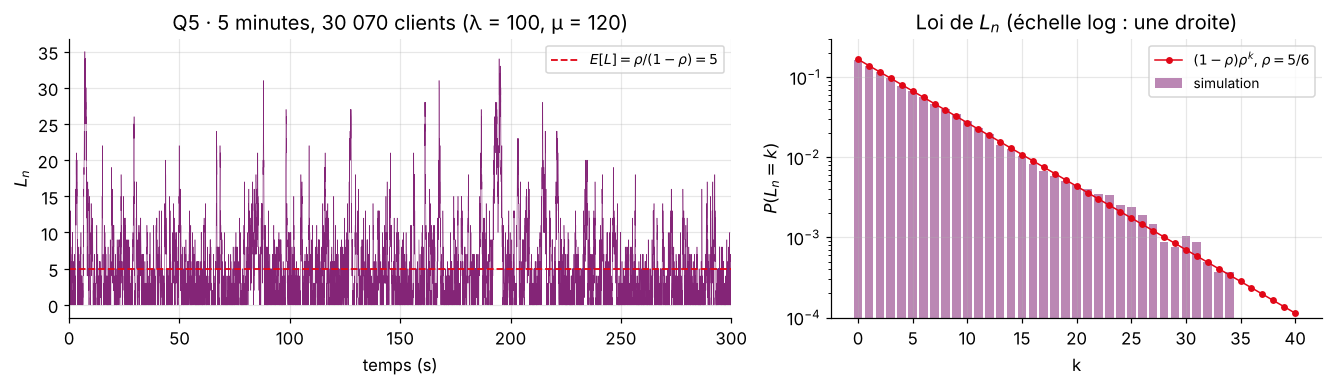

erreur-type naïve 0.0311  contre  par lots 0.3550
autocorrélation à 1, 10, 100, 1000 clients d'écart : 0.972  0.783  0.176  -0.010


In [40]:
print(inspect.getsource(indicateurs_theoriques))

# Q5 : λ = 100 arrivées/s, μ = 120 services/s, 5 minutes à partir d'une file vide
lam, mu, duree = 100.0, 120.0, 300.0
rho = lam / mu                                   # = 5/6 (et non μ/λ : coquille de l'énoncé)
T5, L5 = file_mm1(lam, mu, duree, rng)
th = indicateurs_theoriques(rho)
mesures = {"moyenne": L5, "p_serveur_libre": (L5 == 0), "p_plus_de_5": (L5 > 5)}
print(f"{len(L5)} clients arrivés en 5 min (attendu λ·300 = 30 000) ; plus longue file vue : {L5.max()}")
tableau = {}
for nom, v in mesures.items():
    m, se = moyenne_par_lots(v, 30)              # 30 lots de 10 s environ
    tableau[nom] = dict(theorie=th[nom], simulation=m, se=se, z=(m - th[nom]) / se)
    print(f"{nom:16s} théorie {th[nom]:7.4f}   simulation {m:7.4f} ± {se:.4f}   écart {(m - th[nom])/se:+.2f} e.-t.")
var_sim = L5.var(ddof=1)
print(f"{'variance':16s} théorie {th['variance']:7.4f}   simulation {var_sim:7.4f}")
tableau["variance"] = dict(theorie=th["variance"], simulation=var_sim)
m10 = L5[T5 > 10].mean()
print(f"moyenne sans les 10 premières secondes : {m10:.4f}")
resultats["Q5"] = dict(n=len(L5), max=int(L5.max()), tableau=tableau, moyenne_sans_10s=m10)

kmax = 40
k = np.arange(kmax + 1)
freq = np.array([np.mean(L5 == j) for j in k])
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), layout="constrained", gridspec_kw=dict(width_ratios=[1.35, 1]))
axs[0].plot(T5, L5, color=VIOLET, lw=0.35)
axs[0].axhline(th["moyenne"], color=ROUGE, ls="--", lw=1.2, label=r"$E[L] = \rho/(1-\rho) = 5$")
axs[0].set_title(f"Q5 · 5 minutes, {len(L5):_} clients (λ = 100, μ = 120)".replace("_", " "))
axs[0].set_xlabel("temps (s)"); axs[0].set_ylabel(r"$L_n$"); axs[0].set_xlim(0, duree)
axs[0].legend(fontsize=9, loc="upper right")
axs[1].bar(k, freq, color=VIOLET, alpha=0.55, label="simulation")
axs[1].plot(k, loi_stationnaire(rho, k), "o-", color=ROUGE, ms=3.5, lw=1, label=r"$(1-\rho)\rho^k$, $\rho = 5/6$")
axs[1].set_yscale("log"); axs[1].set_ylim(1e-4, 0.3)
axs[1].set_title("Loi de $L_n$ (échelle log : une droite)"); axs[1].set_xlabel("k")
axs[1].set_ylabel(r"$P(L_n = k)$"); axs[1].legend(fontsize=9)
plt.show()

# Pourquoi les lots ? autocorrélation et erreur-type naïve
se_naive = L5.std(ddof=1) / np.sqrt(len(L5))
ac = [np.corrcoef(L5[:-h], L5[h:])[0, 1] for h in (1, 10, 100, 1000)]
print(f"erreur-type naïve {se_naive:.4f}  contre  par lots {tableau['moyenne']['se']:.4f}")
print("autocorrélation à 1, 10, 100, 1000 clients d'écart :", "  ".join(f"{a:.3f}" for a in ac))

### 📊 Lecture
30 070 clients en 5 minutes ; la file fluctue autour de 5 (pointes à 35) et sa loi suit la droite
$(1-\rho)\rho^k$ sur trois ordres de grandeur.

| quantité | théorie | simulation | écart |
|---|---|---|---|
| $E[L]$ | 5 | $5{,}03 \pm 0{,}36$ | $+0{,}08$ e.-t. |
| $\operatorname{Var}L$ | 30 | $29{,}1$ | |
| $P(L = 0)$ | $0{,}167$ | $0{,}162 \pm 0{,}010$ | $-0{,}51$ e.-t. |
| $P(L > 5)$ | $0{,}335$ | $0{,}340 \pm 0{,}023$ | $+0{,}22$ e.-t. |

L'autocorrélation vaut $0{,}97$ entre deux clients successifs, $0{,}18$ à 100 clients d'écart et
devient négligeable à 1000 : l'erreur-type naïve ($0{,}031$) est **11 fois** trop petite. En clair :
un client sur six trouve le serveur libre, un sur trois trouve plus de 5 personnes devant lui.

### ⚠️ Pièges
- $\rho = \mu/\lambda$ (coquille) : probabilités négatives.
- $P(L > 5) = \rho^5$ : non, $\rho^5 = P(L \ge 5)$.
- Erreur-type naïve $\hat\sigma/\sqrt n$ sur des données corrélées.
- La loi géométrique est la loi **limite** : partir d'une file vide crée un court régime transitoire
  (sans les 10 premières secondes, la moyenne vaut $4{,}88$, dans l'erreur-type).

### ✋ À toi
Un gestionnaire veut que moins de 10 % des clients trouvent plus de 5 personnes devant eux. Avec
$\lambda = 100$, quel $\mu$ faut-il ? Vérifie par simulation (`file_mm1_vectorisee`, 5 min, `rng_exo`).

In [41]:
# rho_max = 0.1 ** (1 / 6) ; mu_min = 100 / rho_max
# _, Lg, _ = file_mm1_vectorisee(100.0, mu_min, 300.0, rng_exo) ; print(moyenne_par_lots(Lg > 5))

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

$\rho^6 \le 0{,}1 \iff \rho \le 0{,}1^{1/6} \approx 0{,}681 \iff \mu \ge 100/0{,}681 \approx 147$ services par
seconde (contre 120 aujourd'hui).
```python
rho_max = 0.1 ** (1 / 6); mu_min = 100 / rho_max
_, Lg, _ = file_mm1_vectorisee(100.0, mu_min, 300.0, rng_exo)
print(mu_min, moyenne_par_lots(Lg > 5))   # ≈ 146,8 et ≈ (0,10, e.-t.)
```

</details>

### 🗣️ La réponse en 30 secondes
<details>
<summary><b>Ce que je dis au jury</b></summary>

« Avec $\rho = 5/6$, la loi stationnaire est géométrique, $(1-\rho)\rho^k$ : je l'ai vérifié en
montrant qu'elle se reproduit par la récurrence, grâce à l'identité $\rho q = p$. On en déduit une
file moyenne de 5, une variance de 30, un client sur six qui trouve le serveur libre et un sur trois
qui trouve plus de 5 clients. La simulation de 5 minutes donne $5{,}03 \pm 0{,}36$, $0{,}162$ et
$0{,}340$, avec des erreurs-types calculées par lots parce que les longueurs successives sont
corrélées. »

</details>

### 🎤 Jury
Questions 14 et 23 à 29 de [questions_oral.md](questions_oral.md). Piège : « Votre erreur-type est
de $0{,}36$ avec 30 000 valeurs, pourquoi si grande ? » (corrélation : méthode des lots).

## Récap

```
 U ~ U[0,1] --(S.1 : -ln(1-U)/λ)--> E(λ)  sans mémoire (A.2), la seule (A.3), E = σ = 1/λ (A.1)
                                     |
            sommes (B.1 convolution) v
 instants T_k ~ Erlang (B.2) --(B.3 : {N_t=k} = {T_k <= t < T_k+1})--> N_t ~ P(λt)
                                     |
            compter les sommes <= 1  v  (S.2)
 simuler P(μ s) = A_n : services possibles entre deux arrivées
                                     |
                                     v
 file M/M/1 : L_{n+1} = max(0, L_n + 1 - A_n)   (Q1, Q2 ; validée par 3 méthodes)
        |                                   |
   ρ = λ/μ > 1                         ρ = λ/μ < 1
   L_n/n -> 1 - 1/ρ (LGN, Q3)          loi -> (1-ρ)ρ^k (Q4, Q5)
   +(λ - μ) clients par seconde        E[L] = ρ/(1-ρ), Var = ρ/(1-ρ)², P(0) = 1-ρ, P(L>5) = ρ^6
```

### Les 5 questions les plus probables

<details>
<summary><b>Que signifie M/M/1 et qu'est-ce que $\rho$ ?</b></summary>

Arrivées poissoniennes, services exponentiels, un serveur, FIFO. $\rho = \lambda/\mu$ = temps de service moyen / temps moyen entre deux arrivées = fraction du temps où le serveur travaille. Tout dépend de $\rho < 1$ ou $> 1$.

</details>

<details>
<summary><b>Expliquez la récurrence $L_{n+1} = (L_n + 1 - A_n)^+$.</b></summary>

Après l'arrivée $n$ il y a $L_n + 1$ clients. Les $A_n$ services possibles avant l'arrivée suivante en font partir $\min(A_n, L_n + 1)$ : le max empêche de descendre sous 0. On a le droit de tirer les services possibles à l'avance grâce à l'absence de mémoire.

</details>

<details>
<summary><b>Pourquoi la file explose-t-elle si $\rho > 1$ ?</b></summary>

$L_n \ge \sum_{k<n}(1 - A_k)$ (Lindley), et par la loi des grands nombres cette somme croît comme $n(1 - 1/\rho)$. En temps : $(\lambda - \mu)t$. Simulé : 1099 clients en 60 s à $\rho = 1{,}2$.

</details>

<details>
<summary><b>D'où vient $(1-\rho)\rho^k$ et que valent les indicateurs ?</b></summary>

On vérifie que cette loi se reproduit par la récurrence (identité $\rho q = p$). Moyenne $\rho/(1-\rho) = 5$, variance $\rho/(1-\rho)^2 = 30$, serveur libre $1 - \rho = 1/6$, plus de 5 clients $\rho^6 = 0{,}335$. Simulé : $5{,}03 \pm 0{,}36$ ; $29{,}1$ ; $0{,}162$ ; $0{,}340$.

</details>

<details>
<summary><b>Pourquoi une erreur-type de $0{,}36$ avec 30 000 valeurs ?</b></summary>

Les longueurs successives sont très corrélées ($0{,}97$) : beaucoup moins de 30 000 informations indépendantes. $\hat\sigma/\sqrt n = 0{,}031$ serait 11 fois trop optimiste ; la méthode des lots (30 blocs de 10 s) corrige.

</details>

**Suite.** C'est le dernier sujet traité pour l'instant. Pour réviser : [fiche_revision.md](fiche_revision.md),
puis entraîne-toi avec les questions de [questions_oral.md](questions_oral.md) (ou demande un oral blanc).